In [1]:
!pip install -U monai
!pip install -q nibabel

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from typing import List, Dict, Sequence, Optional, Tuple
import random
import os
import numpy as np
from tqdm import tqdm
from statistics import mean
import copy

from tqdm import tqdm
import logging

import matplotlib.pyplot as plt

try:
    import nibabel as nib
except ImportError:
    print("ERROR: nibabel library not found. Please install it: pip install nibabel")
    nib = None

# Using MONAI for established deep learning components for medical imaging
# https://monai.io/
from torch.optim import Adam
from monai.losses import DiceLoss, FocalLoss
from monai.metrics import DiceMetric, HausdorffDistanceMetric
from monai.losses import DiceCELoss, DiceLoss, FocalLoss

# Using PyTorch's Automatic Mixed Precision for performance
from torch.cuda.amp import GradScaler
import torch.amp # For autocast
from statistics import mean

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, jaccard_score, accuracy_score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 87.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 62.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 49.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 68.6 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
2025-07-21 03:17:02.591575: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753067822.773478      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753067822.825483      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Using device: cuda
INFO: loadig data from: /kaggle/input/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData
INFO: [BraTSDataset mode='partial_Dm'] Found 200 patients. Limit: 200. ImageCh: 1, SegCh: 3, LoadSeg: True
INFO: [BraTSDataset mode='full_Df'] Found 50 patients. Limit: 50. ImageCh: 1, SegCh: 3, LoadSeg: True
[MetaTrainer] Initialized. AMP: True, Accumulation Steps: 2


/tmp/ipykernel_19/551707898.py:678: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler_G = GradScaler(enabled=self.use_amp)
/tmp/ipykernel_19/551707898.py:679: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler_D = GradScaler(enabled=self.use_amp)
/tmp/ipykernel_19/551707898.py:680: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler_fast_G = GradScaler(enabled=self.use_amp)


> Epoch 1/30


Epoch 1:   0%|          | 0/200 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/monai/utils/deprecate_utils.py:221: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)
Epoch 1: 100%|██████████| 200/200 [09:51<00:00,  2.96s/it, outer_gen=0.9443, outer_seg=0.9388, outer_adv=0.5466, inner_gen=0.9364, discrim=0.6385, DSC=0.0592, HDF95=89.7888]


> Epoch 2/30


Epoch 2: 100%|██████████| 200/200 [08:53<00:00,  2.67s/it, outer_gen=0.9172, outer_seg=0.9133, outer_adv=0.3908, inner_gen=0.9117, discrim=0.5847, DSC=0.1305, HDF95=75.6298]


... (53 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x793594240c20>
Exception ignored in: Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x793594240c20>  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__

Traceback (most recent call last):
      File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers

    if w.is_alive():  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
    if w.is_alive():
 
            ^ ^^^^^^^^^^^^^^^^^^^^^^
^
  File "/usr/lib/python3.11/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.11/multiprocessing/process.py", line 160, in is_alive
        assert self.

> Epoch 30/30


Epoch 30:   0%|          | 0/200 [00:00<?, ?it/s]Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x793594240c20><function _MultiProcessingDataLoaderIter.__del__ at 0x793594240c20>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
    
if w.is_alive():  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers

     if w.is_alive(): 
           ^^ ^^^^^^^^^^^^^^^^^^^^^
^  File "/usr/lib/python3.11/multiprocessing/process.py", line 160, in is_alive

    assert self._parent_pid == os.getpid(), 'can o

INFO: Model saved to /kaggle/working/best_model.pth | DSC improved 0.72%
INFO: --- FO-MAML Adversarial Training Finished ---
INFO: 
--- Evaluating and Plotting for Patient: BraTS20_Training_001 ---


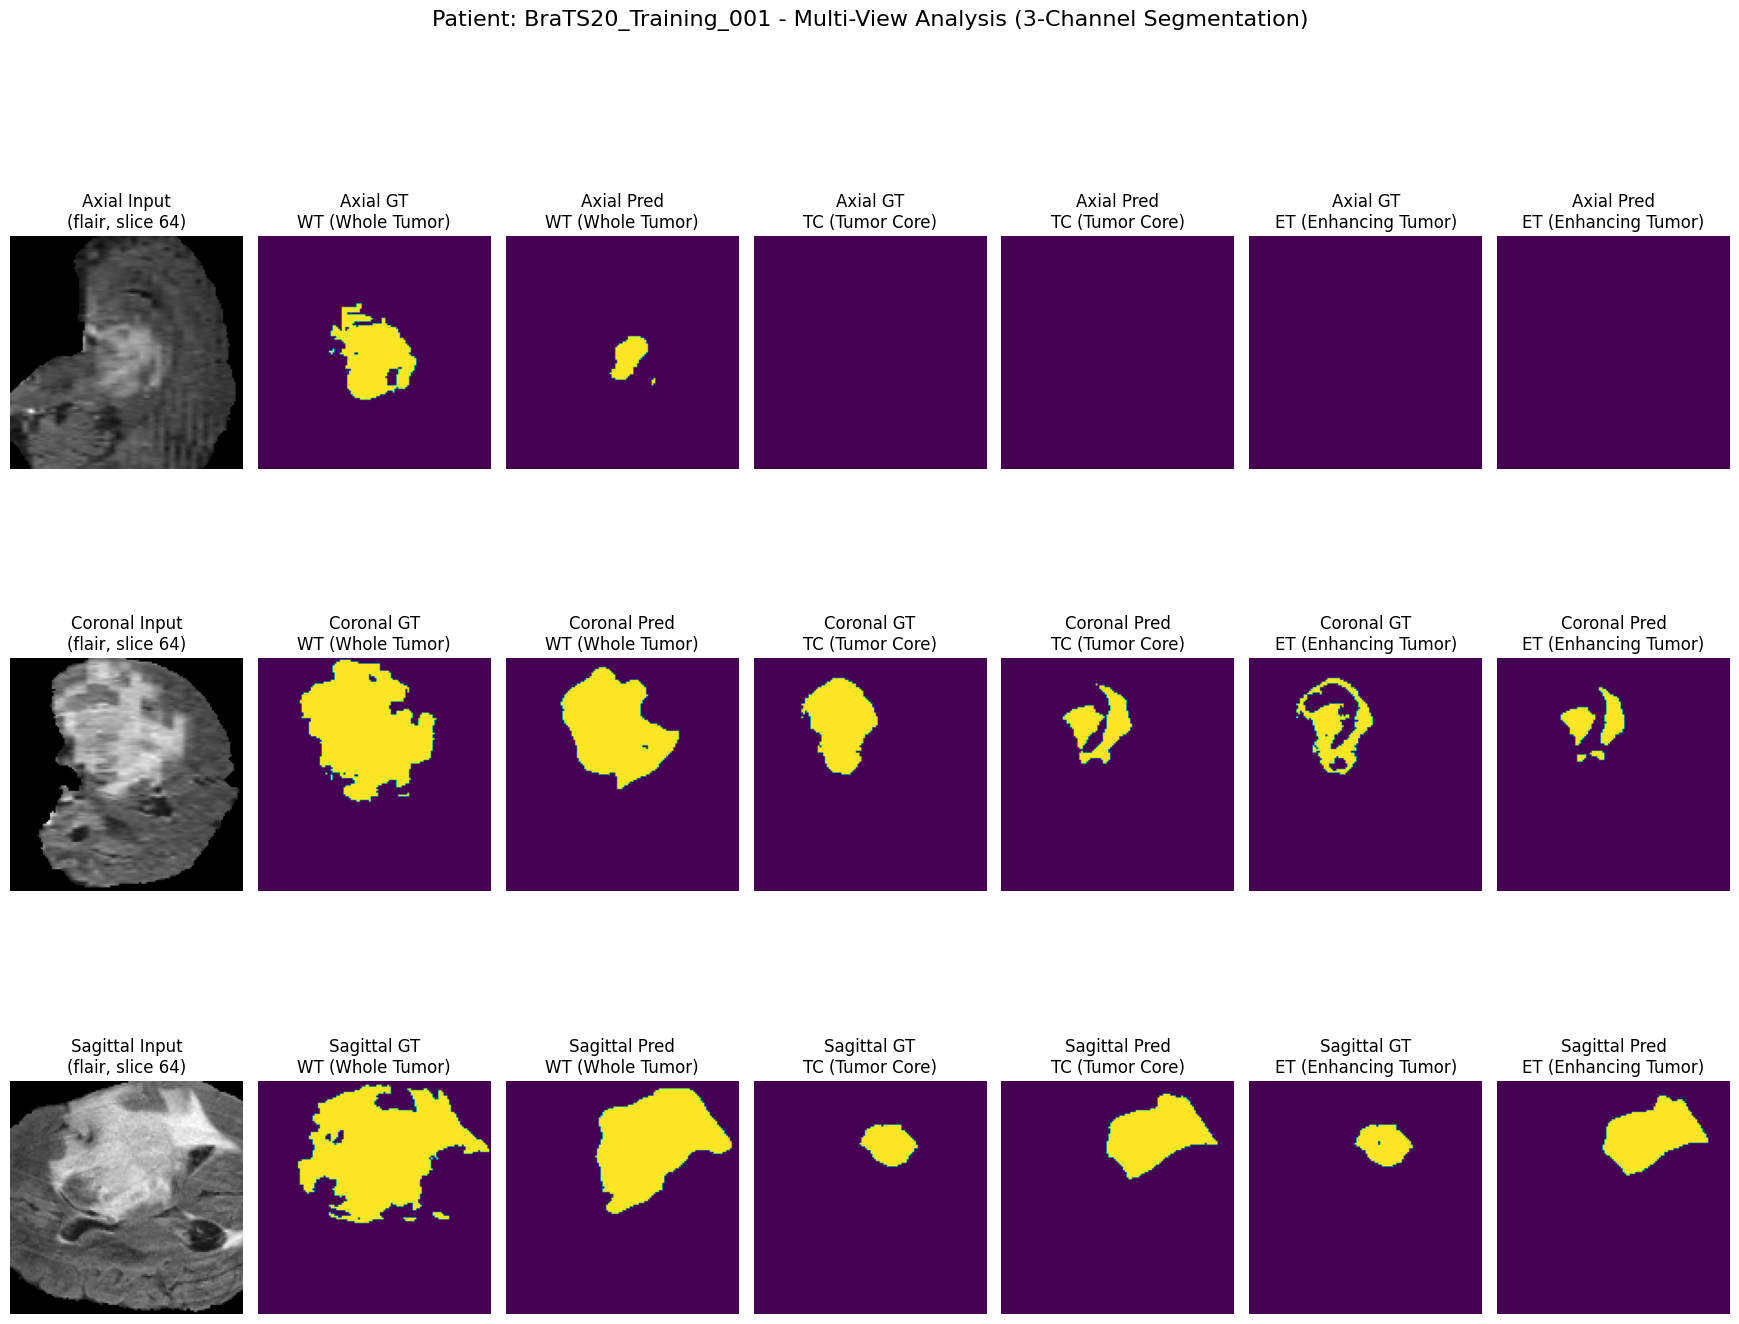

INFO: Multi-view evaluation plot saved as: evaluation_plot_multiview_BraTS20_Training_001_ch3.png
INFO: 
--- Evaluating and Plotting for Patient: BraTS20_Training_001 ---


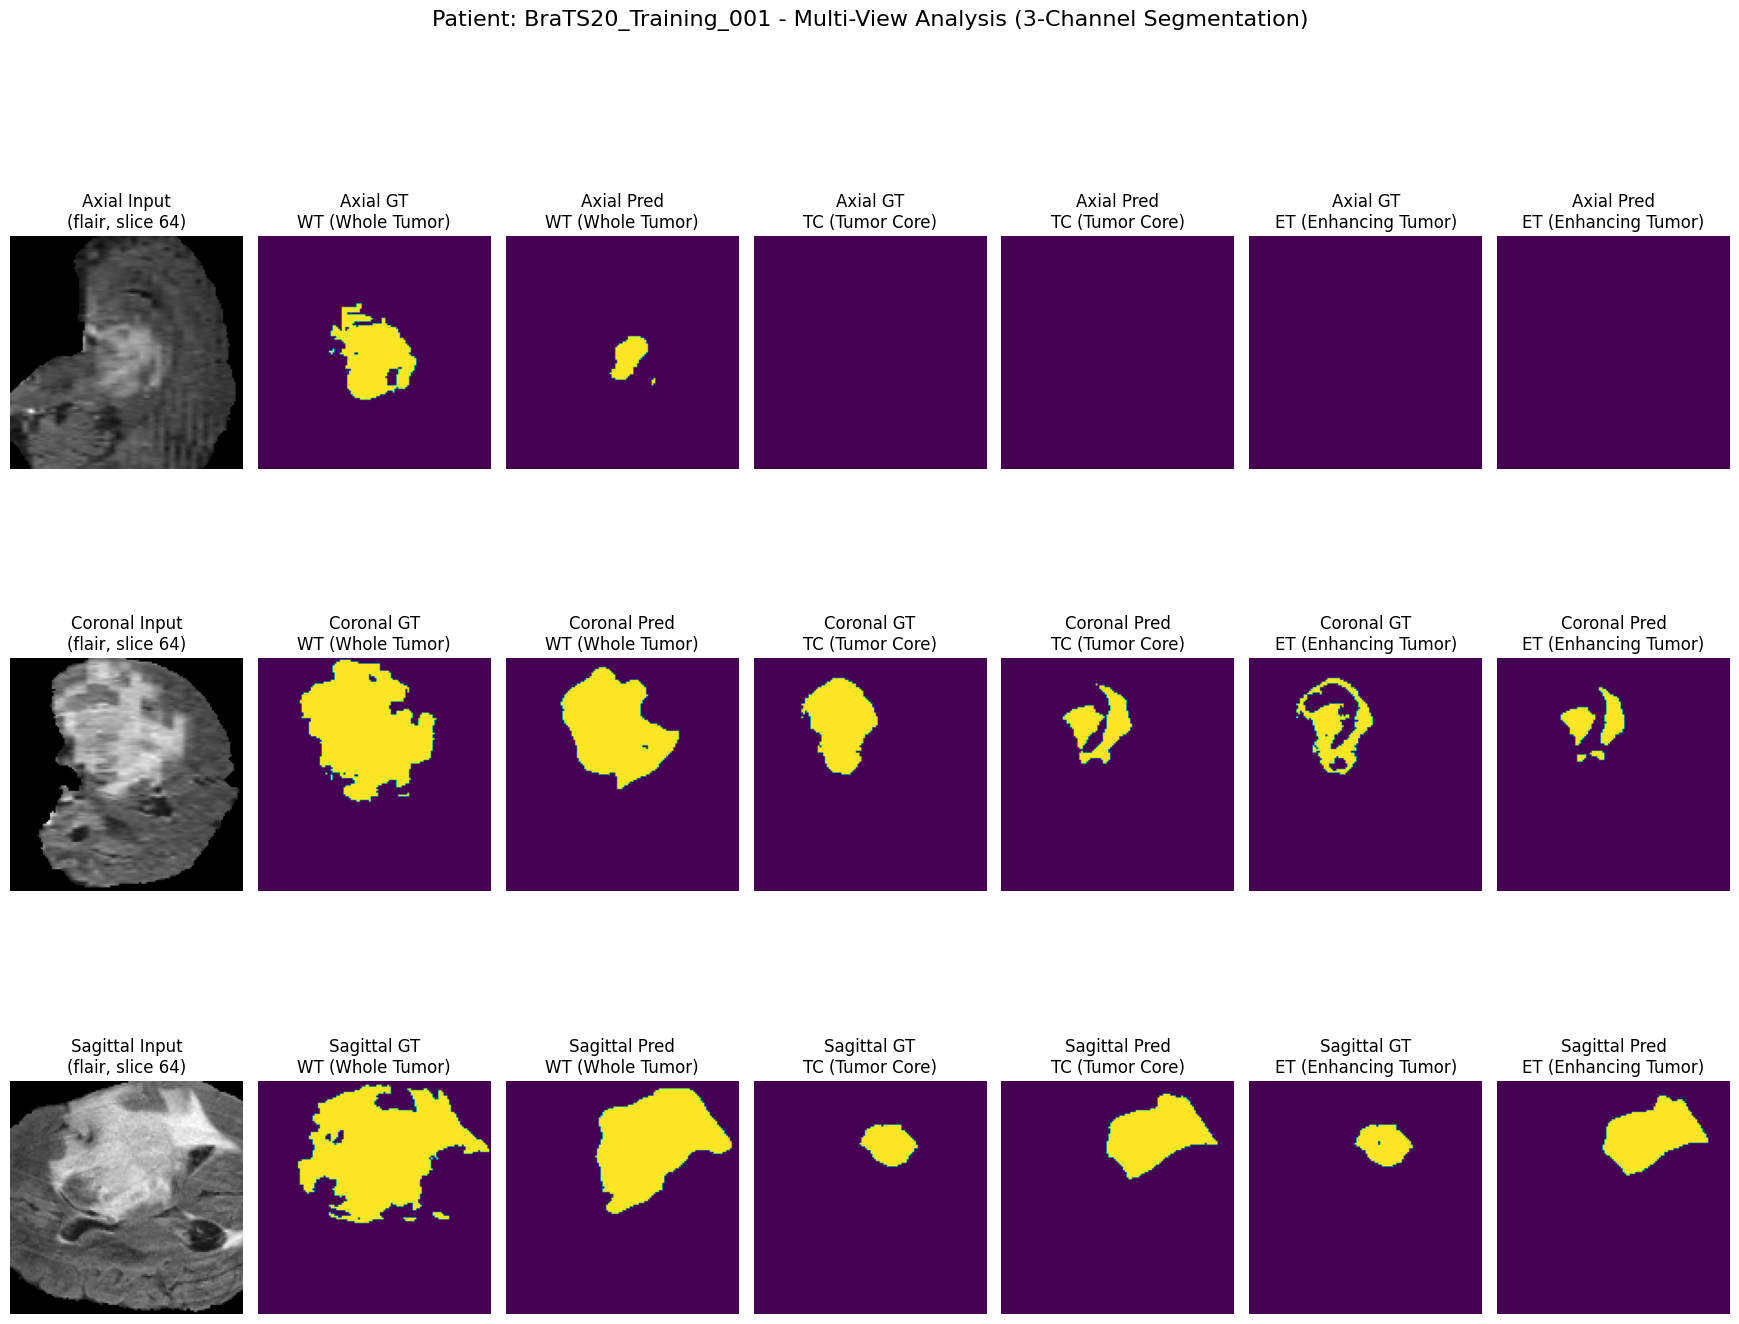

INFO: Multi-view evaluation plot saved as: evaluation_plot_multiview_BraTS20_Training_001_ch3.png


In [2]:
# Default modality names as used in the BraTS dataset
ALL_MODALITY_NAMES_DEFAULT = ("flair", "t1", "t1ce", "t2")

def _preprocess_spatial_utility(data_3d: np.ndarray, target_img_size: Tuple[int, int, int]) -> np.ndarray:
    """
    Spatially crops (from center) or pads a 3D numpy array (D,H,W) to a target size.
    This ensures all images fed to the network have uniform dimensions.
    """
    s, p = [slice(None)] * 3, [(0, 0)] * 3
    cs, ts = data_3d.shape, target_img_size
    for i in range(3):  # Iterate over Depth, Height, Width
        if cs[i] > ts[i]:
            # Crop if the image dimension is larger than the target
            crop_start = (cs[i] - ts[i]) // 2
            s[i] = slice(crop_start, crop_start + ts[i])
        elif cs[i] < ts[i]:
            # Pad if the image dimension is smaller than the target
            pad_before = (ts[i] - cs[i]) // 2
            pad_after = ts[i] - cs[i] - pad_before
            p[i] = (pad_before, pad_after)
    # Apply padding to the (potentially cropped) image
    return np.pad(data_3d[tuple(s)], tuple(p), mode='constant', constant_values=0)

def _create_multilabel_seg_masks_utility(seg_3d:np.ndarray)->np.ndarray:
    """
    Converts a raw integer segmentation mask (e.g., BraTS labels 1, 2, 4)
    into 3 separate binary channels for a multi-label segmentation task.
    - WT (Whole Tumor): Labels 1, 2, 4
    - TC (Tumor Core): Labels 1, 4
    - ET (Enhancing Tumor): Label 4
    """
    # Create binary masks for each tumor region
    wt = np.logical_or.reduce((seg_3d==1, seg_3d==2, seg_3d==4)).astype(np.float32)
    tc = np.logical_or(seg_3d==1, seg_3d==4).astype(np.float32)
    et = (seg_3d==4).astype(np.float32)

    # Ensure we have some tumor voxels
    total_tumor_voxels = np.sum(wt)
    if total_tumor_voxels == 0:
        print("WARNING: No tumor voxels found in segmentation mask!")

    return np.stack([wt, tc, et], 0).astype(np.float32)

def _preprocess_single_nifti_for_eval_utility(file_path: str,
                                             target_img_size: Tuple[int, int, int],
                                             image_output_channels: int,
                                             is_seg: bool = False,
                                             seg_output_channels: int = 3) -> Optional[torch.Tensor]:
    """
    Standalone utility to load and preprocess a single NIfTI file for evaluation,
    handling both images and segmentation masks.
    """
    if not os.path.exists(file_path): return None
    try:
        img_obj = nib.load(file_path)
        img_data_raw_3d = img_obj.get_fdata()

        if not is_seg: # Process as an image
            img_data_raw_3d = img_data_raw_3d.astype(np.float32)
            # Normalize intensity to [0, 1]
            m, M = np.min(img_data_raw_3d), np.max(img_data_raw_3d)
            img_data_norm_3d = (img_data_raw_3d - m) / (M - m) if M > m else np.zeros_like(img_data_raw_3d)
            img_data_spatial_proc_3d = _preprocess_spatial_utility(img_data_norm_3d, target_img_size)
            if image_output_channels == 1: img_final_ch = np.expand_dims(img_data_spatial_proc_3d, 0)
            elif image_output_channels == 3: img_final_ch = np.stack([img_data_spatial_proc_3d]*3, 0)
            else: raise ValueError(f"Unsupported image_output_channels for eval: {image_output_channels}")
            return torch.from_numpy(img_final_ch.copy())
        else: # Process as a segmentation mask
            seg_data_raw_3d = img_data_raw_3d.astype(np.int16)
            seg_data_spatial_proc_3d = _preprocess_spatial_utility(seg_data_raw_3d, target_img_size)
            if seg_output_channels == 3:
                return torch.from_numpy(_create_multilabel_seg_masks_utility(seg_data_spatial_proc_3d).copy())
            elif seg_output_channels == 1:
                return torch.from_numpy(np.expand_dims(seg_data_spatial_proc_3d, 0).astype(np.float32).copy())
            else: raise ValueError(f"Unsupported seg_output_channels: {seg_output_channels}")
    except Exception as e:
        print(f"ERROR: [_preprocess_single_nifti_for_eval_utility] Error loading/processing eval file {file_path}: {e}")
        return None

class nnUNetConvBlock(nn.Module):
    """
    nnU-Net style convolutional block with GroupNorm and LeakyReLU
    """
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1, dropout_p=0.0):
        super().__init__()
        self.conv = nn.Conv3d(in_channels, out_channels, kernel_size, stride, padding, bias=False)
        self.norm = nn.GroupNorm(min(8, out_channels//2), out_channels)
        self.activation = nn.LeakyReLU(negative_slope=0.01, inplace=True)
        self.dropout = nn.Dropout3d(dropout_p) if dropout_p > 0 else nn.Identity()

    def forward(self, x):
        x = self.conv(x)
        x = self.norm(x)
        x = self.activation(x)
        x = self.dropout(x)
        return x

class nnUNetEncoder(nn.Module):
    """
    nnU-Net style encoder with progressive downsampling
    """
    def __init__(self, in_channels=1, base_features=32):
        super().__init__()

        # Feature sizes for each level (following nnU-Net design principles)
        self.features = [base_features * (2**i) for i in range(5)]  # [32, 64, 128, 256, 512]

        # Level 0: Initial convolution
        self.level0 = nn.Sequential(
            nnUNetConvBlock(in_channels, self.features[0]),
            nnUNetConvBlock(self.features[0], self.features[0])
        )

        # Level 1
        self.down1 = nn.Conv3d(self.features[0], self.features[1], 3, stride=2, padding=1, bias=False)
        self.level1 = nn.Sequential(
            nnUNetConvBlock(self.features[1], self.features[1]),
            nnUNetConvBlock(self.features[1], self.features[1])
        )

        # Level 2
        self.down2 = nn.Conv3d(self.features[1], self.features[2], 3, stride=2, padding=1, bias=False)
        self.level2 = nn.Sequential(
            nnUNetConvBlock(self.features[2], self.features[2]),
            nnUNetConvBlock(self.features[2], self.features[2])
        )

        # Level 3
        self.down3 = nn.Conv3d(self.features[2], self.features[3], 3, stride=2, padding=1, bias=False)
        self.level3 = nn.Sequential(
            nnUNetConvBlock(self.features[3], self.features[3]),
            nnUNetConvBlock(self.features[3], self.features[3])
        )

        # Level 4 (bottleneck)
        self.down4 = nn.Conv3d(self.features[3], self.features[4], 3, stride=2, padding=1, bias=False)
        self.level4 = nn.Sequential(
            nnUNetConvBlock(self.features[4], self.features[4]),
            nnUNetConvBlock(self.features[4], self.features[4])
        )

    def forward(self, x):
        # Store skip connections
        skips = []

        # Level 0
        x0 = self.level0(x)
        skips.append(x0)

        # Level 1
        x1 = self.down1(x0)
        x1 = self.level1(x1)
        skips.append(x1)

        # Level 2
        x2 = self.down2(x1)
        x2 = self.level2(x2)
        skips.append(x2)

        # Level 3
        x3 = self.down3(x2)
        x3 = self.level3(x3)
        skips.append(x3)

        # Level 4 (bottleneck)
        x4 = self.down4(x3)
        x4 = self.level4(x4)
        skips.append(x4)

        return skips

class nnUNetDecoder(nn.Module):
    """
    nnU-Net style decoder with progressive upsampling
    """
    def __init__(self, features, out_channels=3):
        super().__init__()
        self.features = features

        # Upsampling layers
        self.up4 = nn.ConvTranspose3d(features[4], features[3], 2, stride=2, bias=False)
        self.decode4 = nn.Sequential(
            nnUNetConvBlock(features[3] + features[3], features[3]),
            nnUNetConvBlock(features[3], features[3])
        )

        self.up3 = nn.ConvTranspose3d(features[3], features[2], 2, stride=2, bias=False)
        self.decode3 = nn.Sequential(
            nnUNetConvBlock(features[2] + features[2], features[2]),
            nnUNetConvBlock(features[2], features[2])
        )

        self.up2 = nn.ConvTranspose3d(features[2], features[1], 2, stride=2, bias=False)
        self.decode2 = nn.Sequential(
            nnUNetConvBlock(features[1] + features[1], features[1]),
            nnUNetConvBlock(features[1], features[1])
        )

        self.up1 = nn.ConvTranspose3d(features[1], features[0], 2, stride=2, bias=False)
        self.decode1 = nn.Sequential(
            nnUNetConvBlock(features[0] + features[0], features[0]),
            nnUNetConvBlock(features[0], features[0])
        )

        # Final output layer
        self.final_conv = nn.Conv3d(features[0], out_channels, 1, bias=False)

    def forward(self, skips):
        # Start from bottleneck
        x = skips[4]

        # Decode level 4->3
        x = self.up4(x)
        x = torch.cat([x, skips[3]], dim=1)
        x = self.decode4(x)

        # Decode level 3->2
        x = self.up3(x)
        x = torch.cat([x, skips[2]], dim=1)
        x = self.decode3(x)

        # Decode level 2->1
        x = self.up2(x)
        x = torch.cat([x, skips[1]], dim=1)
        x = self.decode2(x)

        # Decode level 1->0
        x = self.up1(x)
        x = torch.cat([x, skips[0]], dim=1)
        x = self.decode1(x)

        # Final output
        x = self.final_conv(x)
        return x

class ModalitySharedEncoder(nn.Module):
    """
    nnU-Net based shared encoder that processes each modality independently
    """
    def __init__(self, in_channels=1, base_features=32):
        super().__init__()
        self.encoder = nnUNetEncoder(in_channels, base_features)
        self.features = self.encoder.features

    def forward(self, x_modalities: Dict[str, torch.Tensor]) -> Dict[str, List[torch.Tensor]]:
        """
        Processes a dictionary of modality tensors.
        Returns a dictionary where keys are modality names and values are lists of
        feature maps from different encoder depths.
        """
        encoded_modality_features: Dict[str, List[torch.Tensor]] = {}
        for modality_name, modality_tensor in x_modalities.items():
            # Skip zero tensors (missing modalities)
            if torch.sum(modality_tensor) > 0:
                skips = self.encoder(modality_tensor)
                encoded_modality_features[modality_name] = skips
            else:
                # Create zero feature maps for missing modalities
                batch_size = modality_tensor.shape[0]
                device = modality_tensor.device
                zero_skips = []
                current_size = modality_tensor.shape[2:]  # (D, H, W)

                for i, feat_dim in enumerate(self.features):
                    # Calculate the spatial size at this level
                    spatial_size = [s // (2**i) for s in current_size]
                    zero_skip = torch.zeros(batch_size, feat_dim, *spatial_size, device=device)
                    zero_skips.append(zero_skip)

                encoded_modality_features[modality_name] = zero_skips

        return encoded_modality_features

class FeatureAggregationModule(nn.Module):
    """
    Simplified feature aggregation for nnU-Net features
    """
    def __init__(self, all_modality_names: Sequence[str], feature_dim: int):
        super().__init__()
        self.all_modality_names = all_modality_names
        self.num_total_modalities = len(all_modality_names)
        self.feature_dim = feature_dim

        # Simplified attention mechanism
        self.attention_conv = nn.Conv3d(feature_dim, feature_dim, 1)
        self.attention_norm = nn.GroupNorm(min(8, feature_dim//2), feature_dim)
        self.attention_activation = nn.Sigmoid()

        # Modality weighting
        self.gap = nn.AdaptiveAvgPool3d(1)
        self.weight_mlp = nn.Sequential(
            nn.Conv3d(feature_dim, feature_dim//4, 1),
            nn.LeakyReLU(0.01, inplace=True),
            nn.Conv3d(feature_dim//4, self.num_total_modalities, 1),
            nn.Sigmoid()
        )

    def forward(self, features_dict_level: Dict[str, torch.Tensor]) -> torch.Tensor:
        if not features_dict_level:
            raise ValueError("FeatureAggregationModule received empty dict.")

        # Get reference tensor for shape information
        an_available_tensor = next(iter(features_dict_level.values()))
        batch_size, current_feature_dim, *spatial_dims = an_available_tensor.shape
        device = an_available_tensor.device

        if current_feature_dim != self.feature_dim:
            raise ValueError(f"Expected feature_dim {self.feature_dim}, got {current_feature_dim}")

        # Collect all modality features
        modality_features = []
        for mod_name in self.all_modality_names:
            if mod_name in features_dict_level:
                modality_features.append(features_dict_level[mod_name])
            else:
                # Create zero tensor for missing modality
                zero_feat = torch.zeros_like(an_available_tensor)
                modality_features.append(zero_feat)

        # Stack modalities along a new dimension
        stacked_features = torch.stack(modality_features, dim=1)  # (B, M, C, D, H, W)

        # Compute attention weights for each modality
        pooled_features = self.gap(an_available_tensor)  # (B, C, 1, 1, 1)
        modality_weights = self.weight_mlp(pooled_features)  # (B, M, 1, 1, 1)

        # Apply weights and sum across modalities
        weighted_features = stacked_features * modality_weights.unsqueeze(2)  # (B, M, C, D, H, W)
        fused_features = torch.sum(weighted_features, dim=1)  # (B, C, D, H, W)

        # Apply spatial attention
        attention_map = self.attention_conv(fused_features)
        attention_map = self.attention_norm(attention_map)
        attention_map = self.attention_activation(attention_map)

        return fused_features * attention_map

class Adapter(nn.Module):
    """
    A small, parameter-efficient adapter module. It's a bottleneck feed-forward network
    that is inserted into the main model. During adaptation, only the adapter weights are updated.
    """
    def __init__(self, in_features: int, bottleneck_scale: float = 0.25, init_zeros: bool = True):
        super().__init__()
        bottleneck_dim = max(1, int(in_features * bottleneck_scale))
        self.down_project = nn.Linear(in_features, bottleneck_dim)
        self.non_linearity = nn.ReLU()
        self.up_project = nn.Linear(bottleneck_dim, in_features)
        # Initialize the up-projection to zeros to ensure the adapter is an identity function at the start
        if init_zeros: nn.init.zeros_(self.up_project.weight); nn.init.zeros_(self.up_project.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        original_shape = x.shape; B, C, D, H, W = original_shape
        # Reshape for linear layers: (B, C, D, H, W) -> (B*D*H*W, C)
        x_reshaped = x.permute(0, 2, 3, 4, 1).contiguous().view(-1, C)
        residual = x_reshaped
        x_down = self.down_project(x_reshaped)
        x_nl = self.non_linearity(x_down)
        x_up = self.up_project(x_nl)
        adapted_x_reshaped = residual + x_up # Residual connection
        # Reshape back to original tensor shape
        return adapted_x_reshaped.view(B, D, H, W, C).permute(0, 4, 1, 2, 3).contiguous()

class Generator(nn.Module):
    """
    nnU-Net based Generator that encodes all modalities and fuses them at each level
    """
    def __init__(self, in_channels=1, base_features=32, all_modality_names=ALL_MODALITY_NAMES_DEFAULT,
                 use_adapters: bool = False, adapter_bottleneck_scale: float = 0.25):
        super().__init__()
        self.all_modality_names = list(all_modality_names)
        self.shared_encoder_module = ModalitySharedEncoder(in_channels, base_features)

        # Feature dimensions at each level of the nnU-Net encoder
        self.encoder_feature_dims = self.shared_encoder_module.features

        self.aggregation_modules = nn.ModuleList(
            [FeatureAggregationModule(self.all_modality_names, dim) for dim in self.encoder_feature_dims]
        )

        self.use_adapters = use_adapters
        if self.use_adapters:
            self.level_adapters = nn.ModuleList(
                [Adapter(in_features=dim, bottleneck_scale=adapter_bottleneck_scale) for dim in self.encoder_feature_dims]
            )

    def copy_adapter_weights_from(self, source_generator):
        """Copies adapter weights from another generator instance"""
        if not self.use_adapters or not source_generator.use_adapters:
            raise ValueError("Both generators must have adapters enabled for weight copying")
        
        if len(self.level_adapters) != len(source_generator.level_adapters):
            raise ValueError("Generator adapter count mismatch")
            
        for target_adapter, source_adapter in zip(self.level_adapters, source_generator.level_adapters):
            target_adapter.load_state_dict(source_adapter.state_dict())

    def forward(self, x_modalities: Dict[str, torch.Tensor]) -> List[torch.Tensor]:
        if not x_modalities: return []
        encoded_features = self.shared_encoder_module(x_modalities)
        if not encoded_features or not any(encoded_features.values()): return []

        num_levels = len(next(iter(encoded_features.values())))
        if num_levels != 5: raise ValueError(f"Generator expected 5 levels from encoder, got {num_levels}")

        # Group features by level instead of by modality
        features_by_level = [{} for _ in range(num_levels)]
        for mod_name, levels in encoded_features.items():
            for lvl_idx, feat_map in enumerate(levels):
                # Sanity check for channel dimensions
                if feat_map.shape[1] != self.encoder_feature_dims[lvl_idx]:
                    raise ValueError(f"Channel mismatch for {mod_name} level {lvl_idx}: "
                                     f"expected {self.encoder_feature_dims[lvl_idx]}, got {feat_map.shape[1]}")
                features_by_level[lvl_idx][mod_name] = feat_map

        fused_feature_list = []
        for level_idx in range(num_levels):
            if features_by_level[level_idx]:
                fused_map = self.aggregation_modules[level_idx](features_by_level[level_idx])
                if self.use_adapters: fused_map = self.level_adapters[level_idx](fused_map)
                fused_feature_list.append(fused_map)
            else:
                print(f"WARNING: [Generator.forward] No features to aggregate for level {level_idx}.")
        return fused_feature_list

    def get_adapter_parameters(self):
        """Returns an iterator over the adapter parameters for the optimizer."""
        if self.use_adapters:
            for adapter in self.level_adapters:
                for param in adapter.parameters(): yield param
        else: return iter([])

class ModalityDiscriminator(nn.Module):
    """
    The adversary. A simple classifier that tries to predict which modalities were
    present based on the fused feature map from the generator's bottleneck.
    """
    def __init__(self, bottleneck_feature_dim: int, num_modalities: int, hidden_dim: int = 48):
        super().__init__()
        self.bottleneck_feature_dim = bottleneck_feature_dim
        self.mlp = nn.Sequential(
            nn.AdaptiveAvgPool3d(1), nn.Flatten(),
            nn.Linear(bottleneck_feature_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, num_modalities)
        )

    def forward(self, x_bottleneck_fused: torch.Tensor) -> torch.Tensor:
        if x_bottleneck_fused.shape[1] != self.bottleneck_feature_dim:
            raise ValueError(f"Discriminator input channel mismatch: {x_bottleneck_fused.shape[1]} vs {self.bottleneck_feature_dim}")
        return self.mlp(x_bottleneck_fused)

class SegmentationModel(nn.Module):
    """
    nnU-Net based segmentation model with multi-modality fusion - No upsampling/downsampling
    """
    def __init__(self, in_channels=1, out_channels=3, base_features=32,
                 all_possible_modality_names=ALL_MODALITY_NAMES_DEFAULT,
                 use_adapters_in_generator: bool = False):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.base_features = base_features

        # nnU-Net based generator for multi-modality feature extraction and fusion
        self.generator = Generator(in_channels, base_features, all_possible_modality_names,
                                   use_adapters=use_adapters_in_generator)

        # nnU-Net decoder
        self.decoder = nnUNetDecoder(self.generator.encoder_feature_dims, out_channels)

    def forward(self, x_modalities: Dict[str, torch.Tensor]) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Forward pass through the nnU-Net based segmentation model
        """
        # Get fused features from generator
        fused_skips = self.generator(x_modalities)
        if len(fused_skips) != 5:
            raise ValueError(f"Generator expected 5 skips, got {len(fused_skips)}")

        # Use deepest feature for discriminator
        bottleneck_for_D = fused_skips[4]

        # Decode to get segmentation
        segmentation_logits = self.decoder(fused_skips)

        return segmentation_logits, bottleneck_for_D

class BraTSDataset(Dataset):
    """
    Custom PyTorch Dataset for the BraTS dataset with consistent dimension handling
    """
    def __init__(self, data_root_dir: str, mode: str = 'partial_Dm',
                 num_patients_to_load: Optional[int] = None,
                 num_modalities_to_select_partial: int = 3,
                 target_img_size: Tuple[int, int, int] = (128, 128, 128),  # Consistent target size
                 all_possible_modality_keys: List[str] = list(ALL_MODALITY_NAMES_DEFAULT),
                 image_output_channels: int = 1, seg_output_channels: int = 3,
                 load_segmentation: bool = True):
        super().__init__()
        if nib is None: raise ImportError("nibabel required for BraTSDataset.")
        self.data_root_dir, self.mode = data_root_dir, mode
        self.num_modalities_to_select_partial = num_modalities_to_select_partial
        self.target_img_size, self.all_possible_modality_keys = target_img_size, all_possible_modality_keys
        self.image_output_channels, self.seg_output_channels = image_output_channels, seg_output_channels
        self.load_segmentation = load_segmentation
        self.modality_file_suffixes = {"flair":"_flair.nii", "t1":"_t1.nii", "t1ce":"_t1ce.nii", "t2":"_t2.nii"}
        self.seg_file_suffix = "_seg.nii"

        try:
            self.patient_folders = sorted([
                os.path.join(self.data_root_dir, d) for d in os.listdir(self.data_root_dir)
                if os.path.isdir(os.path.join(self.data_root_dir, d)) and (d.startswith("BraTS20_Training_") or d.startswith("BraTS20_Validation_") )
            ])
        except FileNotFoundError: self.patient_folders = []

        # Optionally limit the number of patients to use for quick experiments
        if num_patients_to_load is not None: self.patient_folders = self.patient_folders[:num_patients_to_load]
        print(f"INFO: [BraTSDataset mode='{self.mode}'] Found {len(self.patient_folders)} patients. Limit: {num_patients_to_load}. "
              f"ImageCh: {self.image_output_channels}, SegCh: {self.seg_output_channels}, LoadSeg: {self.load_segmentation}")
        if not self.patient_folders: print(f"WARNING: [BraTSDataset] No patient folders found in {self.data_root_dir}.")

    def __len__(self) -> int: return len(self.patient_folders)

    def __getitem__(self, idx: int) -> Tuple[Dict[str, torch.Tensor], torch.Tensor, Optional[torch.Tensor]]:
        patient_id_prefix = os.path.basename(self.patient_folders[idx])
        out_modalities, actual_loaded = {}, {}
        img_zero_shape = (self.image_output_channels, *self.target_img_size)
        mod_gt = torch.zeros(len(self.all_possible_modality_keys), dtype=torch.float32)

        # Load all available modalities for the patient at target resolution
        for i_key, mod_key in enumerate(self.all_possible_modality_keys):
            fp_nii = os.path.join(self.patient_folders[idx], f"{patient_id_prefix}{self.modality_file_suffixes.get(mod_key)}")
            fp_niigz = fp_nii + ".gz"; fp_to_load = None
            if os.path.exists(fp_nii): fp_to_load = fp_nii
            elif os.path.exists(fp_niigz): fp_to_load = fp_niigz
            if fp_to_load:
                try:
                    img_3d = nib.load(fp_to_load).get_fdata(dtype=np.float32)

                    # Apply intensity normalization
                    m, M = np.min(img_3d), np.max(img_3d)
                    img_3d_norm = (img_3d-m)/(M-m) if M>m else np.zeros_like(img_3d)

                    # Apply spatial preprocessing to ensure consistent size
                    img_3d_spatial = _preprocess_spatial_utility(img_3d_norm, self.target_img_size)

                    # Add channel dimension
                    if self.image_output_channels==1:
                        img_final_ch = np.expand_dims(img_3d_spatial, 0)
                    elif self.image_output_channels==3:
                        img_final_ch = np.stack([img_3d_spatial]*3, 0)
                    else:
                        raise ValueError("image_output_channels must be 1 or 3")

                    actual_loaded[mod_key] = torch.from_numpy(img_final_ch.copy())
                except Exception as e:
                    print(f"ERROR: [BraTSDataset] Err load img {fp_to_load} for patient {patient_id_prefix}: {e}")

        loaded_keys = list(actual_loaded.keys())
        if self.mode == 'partial_Dm':
            sel_keys = random.sample(loaded_keys, min(self.num_modalities_to_select_partial, len(loaded_keys)))
        elif self.mode == 'full_Df':
            if len(loaded_keys) < len(self.all_possible_modality_keys):
                 print(f"WARNING: [BraTSDataset] Patient {patient_id_prefix} (full_Df) has {len(loaded_keys)}/{len(self.all_possible_modality_keys)} mods. Using available.")
            sel_keys = loaded_keys
        else: raise ValueError(f"Unknown dataset mode: {self.mode}")

        # Create output dictionary with all modality keys
        for i_key, mod_key in enumerate(self.all_possible_modality_keys):
            if mod_key in sel_keys and mod_key in actual_loaded:
                out_modalities[mod_key] = actual_loaded[mod_key]
                mod_gt[i_key] = 1.0
            else:
                out_modalities[mod_key] = torch.zeros(img_zero_shape, dtype=torch.float32)

        # Load segmentation mask at target resolution if required
        seg_tensor = None
        if self.load_segmentation:
            seg_fp_nii = os.path.join(self.patient_folders[idx], f"{patient_id_prefix}{self.seg_file_suffix}")
            seg_fp_niigz = seg_fp_nii + ".gz"; seg_fp_to_load = None
            if os.path.exists(seg_fp_nii): seg_fp_to_load = seg_fp_nii
            elif os.path.exists(seg_fp_niigz): seg_fp_to_load = seg_fp_niigz
            if seg_fp_to_load:
                try:
                    seg_3d = nib.load(seg_fp_to_load).get_fdata().astype(np.int16)

                    # Apply spatial preprocessing to ensure consistent size
                    seg_3d_spatial = _preprocess_spatial_utility(seg_3d, self.target_img_size)

                    if self.seg_output_channels == 3:
                        seg_tensor = torch.from_numpy(_create_multilabel_seg_masks_utility(seg_3d_spatial).copy())
                    elif self.seg_output_channels == 1:
                        # For single channel, convert multi-class to binary (any tumor vs background)
                        binary_seg = (seg_3d_spatial > 0).astype(np.float32)
                        seg_tensor = torch.from_numpy(np.expand_dims(binary_seg, 0).copy())
                    else:
                        raise ValueError("seg_output_channels must be 1 or 3")

                    # Validate tensor values are in correct range
                    seg_min, seg_max = torch.min(seg_tensor), torch.max(seg_tensor)
                    if seg_min < 0 or seg_max > 1:
                        print(f"WARNING: Segmentation values out of range [0,1]: min={seg_min}, max={seg_max}")
                        seg_tensor = torch.clamp(seg_tensor, 0, 1)

                except Exception as e:
                    print(f"ERROR: [BraTSDataset] Failed to load segmentation {seg_fp_to_load} for patient {patient_id_prefix}: {e}")
                    seg_tensor = None
            else:
                print(f"WARNING: [BraTSDataset] Seg file not found for {patient_id_prefix}")

            if seg_tensor is None:
                print(f"WARNING: [BraTSDataset] Creating dummy zero segmentation mask ({self.seg_output_channels} ch) for {patient_id_prefix}")
                seg_tensor = torch.zeros((self.seg_output_channels, *self.target_img_size), dtype=torch.float32)

        return out_modalities, mod_gt, seg_tensor

class MetaTrainer:
    """
    Simplified meta-trainer for nnU-Net based architecture with consistent dimension handling
    """
    def __init__(self,
                 segmentation_model: SegmentationModel,
                 discriminator_model: ModalityDiscriminator,
                 dataloader_Dm: DataLoader,
                 dataloader_Df: DataLoader,
                 device: torch.device,
                 lr_meta_G: float = 1e-4,
                 lr_D: float = 1e-4,
                 lr_alpha_inner: float = 1e-3,
                 lambda_seg: float = 1.0,
                 lambda_adv_g: float = 0.1,
                 seg_output_channels_for_loss: int = 3,
                 inner_loop_k_steps: int = 1,
                 use_amp: bool = False,
                 accumulation_steps: int = 1):

        self.segmentation_model = segmentation_model.to(device)
        self.discriminator_model = discriminator_model.to(device)
        self.dataloader_Dm = dataloader_Dm
        self.dataloader_Df = dataloader_Df
        self.device = device
        self.lr_alpha_inner = lr_alpha_inner
        self.lambda_seg = lambda_seg
        self.lambda_adv_g = lambda_adv_g
        self.seg_output_channels_for_loss = seg_output_channels_for_loss
        self.inner_loop_k_steps = inner_loop_k_steps
        self.use_adapters = self.segmentation_model.generator.use_adapters

        self.use_amp = use_amp if device.type == 'cuda' else False
        self.accumulation_steps = accumulation_steps

        # Initialize history trackers
        self.epoch_loss_history = {
            "outer_gen": [],
            "outer_seg": [],
            "outer_adv": [],
            "discrim": [],
            "inner_gen": []
        }
        self.epoch_dice_history = []
        self.epoch_hd_history = []
        self.best_dsc = -1.0  # Initialize best DSC

        # Optimizers
        self.meta_optimizer_G = Adam(self.segmentation_model.parameters(), lr=lr_meta_G)
        self.optimizer_D = Adam(self.discriminator_model.parameters(), lr=lr_D)
        
        # Loss functions
        self.criterion_bce_with_logits = nn.BCEWithLogitsLoss()
        if self.seg_output_channels_for_loss == 1:
            self.criterion_seg = DiceLoss(sigmoid=False, include_background=True, reduction='mean')
        elif self.seg_output_channels_for_loss == 3:
            self.criterion_seg = DiceLoss(sigmoid=True, include_background=True, reduction='mean')
        else: 
            raise ValueError("Unsupported seg_output_channels_for_loss")

        # GradScalers for Automatic Mixed Precision
        self.scaler_G = GradScaler(enabled=self.use_amp)
        self.scaler_D = GradScaler(enabled=self.use_amp)
        self.scaler_fast_G = GradScaler(enabled=self.use_amp)
        
        print(f"[MetaTrainer] Initialized. AMP: {self.use_amp}, Accumulation Steps: {self.accumulation_steps}")

    def _run_segmentation_pathway_with_specific_generator(self, generator_instance, x_modalities_device):
        """Helper function to run forward pass with a specific generator instance"""
        # Get fused features from generator
        fused_skips = generator_instance(x_modalities_device)
        if len(fused_skips) != 5:
            raise ValueError(f"Generator expected 5 skips, got {len(fused_skips)}")

        bottleneck_for_D = fused_skips[4]

        # Decode to get segmentation
        segmentation_logits = self.segmentation_model.decoder(fused_skips)

        return segmentation_logits, bottleneck_for_D

    def _calculate_generator_combined_loss(self, seg_logits, seg_gt, d_logits_on_g) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """Calculates the combined segmentation and adversarial loss for the generator."""
        loss_seg = torch.tensor(0.0, device=self.device)
        if seg_gt is not None and self.lambda_seg > 0:
            if seg_logits.shape[2:] != seg_gt.shape[2:]:
                print(f"WARNING: Shape mismatch - seg_logits: {seg_logits.shape}, seg_gt: {seg_gt.shape}")
                seg_logits_resized = F.interpolate(seg_logits, size=seg_gt.shape[2:], mode='trilinear', align_corners=False)
                loss_seg = self.criterion_seg(seg_logits_resized, seg_gt)
            else:
                loss_seg = self.criterion_seg(seg_logits, seg_gt)

        target_all_present = torch.ones_like(d_logits_on_g, device=self.device)
        loss_adv_g = self.criterion_bce_with_logits(d_logits_on_g, target_all_present)
        total_g_loss = self.lambda_seg * loss_seg + self.lambda_adv_g * loss_adv_g
        return total_g_loss, loss_seg, loss_adv_g

    def train_epoch(self, epoch: int):
        self.segmentation_model.train()
        self.discriminator_model.train()
        iter_dataloader_Df = iter(self.dataloader_Df)

        epoch_losses = {
            "outer_gen": [], "outer_seg": [], "outer_adv": [],
            "discrim": [], "inner_gen": []
        }
        epoch_dice_scores = []
        epoch_hd_scores = []

        total_batches = len(self.dataloader_Dm)
        print(f"> Epoch {epoch+1}/{self.num_epochs_total}")

        if self.accumulation_steps > 1:
            self.meta_optimizer_G.zero_grad()
            self.optimizer_D.zero_grad()

        # Track best DSC for model saving
        if not hasattr(self, "best_dsc"):
            self.best_dsc = -1.0

        with tqdm(
                enumerate(self.dataloader_Dm),
                total=total_batches,
                desc=f"Epoch {epoch+1}"
            ) as t:
                for batch_idx_Dm, (batch_data_Dm_cpu, mod_gt_Dm_cpu, seg_gt_Dm_cpu) in t:
                    batch_data_Dm_device = {k: v.to(self.device) for k, v in batch_data_Dm_cpu.items()}
                    mod_gt_Dm_device = mod_gt_Dm_cpu.to(self.device)
                    seg_gt_Dm_device = seg_gt_Dm_cpu.to(self.device) if seg_gt_Dm_cpu is not None else None

                    if self.use_adapters:
                        fast_generator = Generator(
                            in_channels=self.segmentation_model.generator.shared_encoder_module.encoder.level0[0].conv.in_channels,
                            base_features=self.segmentation_model.generator.shared_encoder_module.encoder.features[0],
                            all_modality_names=self.segmentation_model.generator.all_modality_names,
                            use_adapters=True,
                            adapter_bottleneck_scale=self.segmentation_model.generator.level_adapters[0].down_project.out_features /
                                                    self.segmentation_model.generator.level_adapters[0].down_project.in_features
                        ).to(self.device)
                        fast_generator.copy_adapter_weights_from(self.segmentation_model.generator)
                        for param in fast_generator.parameters():
                            param.requires_grad = False
                        for adapter in fast_generator.level_adapters:
                            for param in adapter.parameters():
                                param.requires_grad = True
                        optimizer_fast_G = Adam(fast_generator.get_adapter_parameters(), lr=self.lr_alpha_inner)
                    else:
                        fast_generator = copy.deepcopy(self.segmentation_model.generator)
                        optimizer_fast_G = Adam(fast_generator.parameters(), lr=self.lr_alpha_inner)

                    for k in range(self.inner_loop_k_steps):
                        optimizer_fast_G.zero_grad()
                        with torch.amp.autocast(self.device.type, enabled=self.use_amp):
                            seg_logits_inner, bottleneck_inner = self._run_segmentation_pathway_with_specific_generator(fast_generator, batch_data_Dm_device)
                            d_logits_on_fast_g_inner = self.discriminator_model(bottleneck_inner)
                            loss_g_inner, _, _ = self._calculate_generator_combined_loss(seg_logits_inner, seg_gt_Dm_device, d_logits_on_fast_g_inner)
                        self.scaler_fast_G.scale(loss_g_inner).backward()
                        self.scaler_fast_G.step(optimizer_fast_G)
                        self.scaler_fast_G.update()

                    try:
                        batch_data_Df_cpu, _, seg_gt_Df_cpu = next(iter_dataloader_Df)
                    except StopIteration:
                        iter_dataloader_Df = iter(self.dataloader_Df)
                        batch_data_Df_cpu, _, seg_gt_Df_cpu = next(iter_dataloader_Df)
                    batch_data_Df_device = {k: v.to(self.device) for k, v in batch_data_Df_cpu.items()}
                    seg_gt_Df_device = seg_gt_Df_cpu.to(self.device) if seg_gt_Df_cpu is not None else None

                    with torch.amp.autocast(self.device.type, enabled=self.use_amp):
                        seg_logits_outer, bottleneck_outer = self._run_segmentation_pathway_with_specific_generator(fast_generator, batch_data_Df_device)
                        d_logits_on_fast_g_outer = self.discriminator_model(bottleneck_outer)
                        loss_g_outer_L_full, loss_seg_outer, loss_adv_g_outer = self._calculate_generator_combined_loss(
                            seg_logits_outer, seg_gt_Df_device, d_logits_on_fast_g_outer
                        )

                    loss_g_outer_L_full_scaled_for_accum = loss_g_outer_L_full / self.accumulation_steps
                    self.scaler_G.scale(loss_g_outer_L_full_scaled_for_accum).backward()

                    if (batch_idx_Dm + 1) % self.accumulation_steps == 0:
                        self.scaler_G.step(self.meta_optimizer_G)
                        self.scaler_G.update()
                        self.meta_optimizer_G.zero_grad()

                    self.optimizer_D.zero_grad()
                    with torch.no_grad(), torch.amp.autocast(self.device.type, enabled=self.use_amp):
                        _, bottleneck_for_D_on_Dm = self.segmentation_model(batch_data_Dm_device)

                    with torch.amp.autocast(self.device.type, enabled=self.use_amp):
                        d_logits_for_d_update = self.discriminator_model(bottleneck_for_D_on_Dm.detach())
                        loss_d = self.criterion_bce_with_logits(d_logits_for_d_update, mod_gt_Dm_device)

                    loss_d_scaled_for_accum = loss_d / self.accumulation_steps
                    self.scaler_D.scale(loss_d_scaled_for_accum).backward()

                    if (batch_idx_Dm + 1) % self.accumulation_steps == 0:
                        self.scaler_D.step(self.optimizer_D)
                        self.scaler_D.update()
                        self.optimizer_D.zero_grad()

                    # Store loss values
                    epoch_losses["outer_gen"].append(loss_g_outer_L_full.item())
                    epoch_losses["outer_seg"].append(loss_seg_outer.item())
                    epoch_losses["outer_adv"].append(loss_adv_g_outer.item())
                    epoch_losses["discrim"].append(loss_d.item())
                    epoch_losses["inner_gen"].append(loss_g_inner.item())

                    if seg_gt_Df_device is not None:
                        with torch.no_grad(), torch.amp.autocast(self.device.type, enabled=self.use_amp):
                            seg_probs_outer = torch.sigmoid(seg_logits_outer)
                            seg_preds_outer_binarized = (seg_probs_outer > 0.5).float()

                            if seg_probs_outer.shape[2:] != seg_gt_Df_device.shape[2:]:
                                seg_gt_Df_resized_for_metrics = F.interpolate(seg_gt_Df_device, size=seg_probs_outer.shape[2:], mode='nearest')
                            else:
                                seg_gt_Df_resized_for_metrics = seg_gt_Df_device

                            dice_score = DiceMetric(include_background=False)(seg_preds_outer_binarized, seg_gt_Df_resized_for_metrics)
                            hd_score = HausdorffDistanceMetric(include_background=False, percentile=95.0)(seg_preds_outer_binarized, seg_gt_Df_resized_for_metrics)

                            epoch_dice_scores.append(dice_score)
                            epoch_hd_scores.append(hd_score)

                    # --- tqdm bar update ---
                    mean_outer_gen = mean(epoch_losses["outer_gen"]) if epoch_losses["outer_gen"] else 0.0
                    mean_outer_seg = mean(epoch_losses["outer_seg"]) if epoch_losses["outer_seg"] else 0.0
                    mean_outer_adv = mean(epoch_losses["outer_adv"]) if epoch_losses["outer_adv"] else 0.0
                    mean_inner_gen = mean(epoch_losses["inner_gen"]) if epoch_losses["inner_gen"] else 0.0
                    mean_discrim = mean(epoch_losses["discrim"]) if epoch_losses["discrim"] else 0.0

                    mean_dice = 0.0
                    if epoch_dice_scores:
                        dice_tensor = torch.cat(epoch_dice_scores, dim=0)
                        mean_dice_per_class = torch.nanmean(dice_tensor, dim=0)
                        mean_dice = torch.nanmean(mean_dice_per_class).item()

                    mean_hd = 0.0
                    if epoch_hd_scores:
                        hd_tensor = torch.cat(epoch_hd_scores, dim=0)
                        valid_hd = hd_tensor[~torch.isinf(hd_tensor) & ~torch.isnan(hd_tensor)]
                        if valid_hd.numel() > 0:
                            mean_hd = torch.mean(valid_hd).item()

                    t.set_postfix({
                        "outer_gen": f"{mean_outer_gen:.4f}",
                        "outer_seg": f"{mean_outer_seg:.4f}",
                        "outer_adv": f"{mean_outer_adv:.4f}",
                        "inner_gen": f"{mean_inner_gen:.4f}",
                        "discrim": f"{mean_discrim:.4f}",
                        "DSC": f"{mean_dice:.4f}",
                        "HDF95": f"{mean_hd:.4f}"
                    })

                # Save model if DSC improves
                if mean_dice > self.best_dsc:
                    prev_best = self.best_dsc
                    self.best_dsc = mean_dice
                    save_path = "/kaggle/working/best_model.pth"
                    torch.save({
                        "segmentation_model": self.segmentation_model.state_dict(),
                        "discriminator_model": self.discriminator_model.state_dict(),
                        "epoch": epoch,
                        "best_dsc": self.best_dsc,
                    }, save_path)
                    if prev_best > 0:
                        percent_increase = 100 * (self.best_dsc - prev_best) / prev_best
                        print(f"INFO: Model saved to {save_path} | DSC improved {percent_increase:.2f}%")

        # Store epoch metrics
        if epoch_losses["outer_gen"]:
            self.epoch_loss_history["outer_gen"].append(np.mean(epoch_losses["outer_gen"]))
            self.epoch_loss_history["outer_seg"].append(np.mean(epoch_losses["outer_seg"]))
            self.epoch_loss_history["outer_adv"].append(np.mean(epoch_losses["outer_adv"]))
            self.epoch_loss_history["discrim"].append(np.mean(epoch_losses["discrim"]))
            self.epoch_loss_history["inner_gen"].append(np.mean(epoch_losses["inner_gen"]))
        
        if epoch_dice_scores:
            dice_tensor = torch.cat(epoch_dice_scores, dim=0)
            mean_dice_per_class = torch.nanmean(dice_tensor, dim=0)
            self.epoch_dice_history.append(torch.nanmean(mean_dice_per_class).item())
        else:
            self.epoch_dice_history.append(0.0)

        if epoch_hd_scores:
            hd_tensor = torch.cat(epoch_hd_scores, dim=0)
            valid_hd = hd_tensor[~torch.isinf(hd_tensor) & ~torch.isnan(hd_tensor)]
            self.epoch_hd_history.append(torch.mean(valid_hd).item() if valid_hd.numel() > 0 else float('inf'))
        else:
            self.epoch_hd_history.append(float('inf'))

    def train(self, num_epochs: int):
        self.num_epochs_total = num_epochs
        for epoch in range(num_epochs):
            self.train_epoch(epoch)
        print("INFO: --- FO-MAML Adversarial Training Finished ---")

    def evaluate_and_plot(self,
                          image_file_paths: Dict[str, str],
                          ground_truth_seg_path: Optional[str],
                          patient_id: str = "TestPatient",
                          slice_idx_to_plot: Optional[int] = None):
        """
        Performs inference on a single patient case and generates a plot comparing
        input, prediction, and ground truth in three anatomical views: axial, coronal, sagittal.
        """
        if nib is None or plt is None:
            print("WARNING: [MetaTrainer.evaluate_and_plot] nibabel or matplotlib not found. Skipping.")
            return
        print(f"INFO: \n--- Evaluating and Plotting for Patient: {patient_id} ---")
        self.segmentation_model.eval()

        # Use the same target size as training data
        target_img_size = (128, 128, 128)  # Match the training target size (D, H, W)
        image_input_channels = self.segmentation_model.in_channels
        all_model_modality_keys = list(self.segmentation_model.generator.all_modality_names)
        seg_output_channels = self.segmentation_model.out_channels

        model_input_dict_device: Dict[str, torch.Tensor] = {}
        loaded_modality_for_display_key = None
        reference_display_tensor_cpu = None
        for mod_key in all_model_modality_keys:
            if mod_key in image_file_paths:
                # Load and preprocess to target size
                tensor_data = _preprocess_single_nifti_for_eval_utility(image_file_paths[mod_key], target_img_size, image_input_channels)
                if tensor_data is not None:
                    model_input_dict_device[mod_key] = tensor_data.unsqueeze(0).to(self.device)
                    if loaded_modality_for_display_key is None:
                        loaded_modality_for_display_key = mod_key
                        reference_display_tensor_cpu = tensor_data.cpu().numpy()
            else:
                # Create zero tensor at target size for missing modalities
                model_input_dict_device[mod_key] = torch.zeros(
                    (1, image_input_channels, *target_img_size),
                    device=self.device,
                    dtype=torch.float32
                )

        if not loaded_modality_for_display_key:
            print(f"ERROR: [MetaTrainer.evaluate_and_plot] No valid image modalities provided or loaded for patient {patient_id} evaluation plot.")
            return

        ground_truth_mask = None
        if ground_truth_seg_path:
             ground_truth_mask = _preprocess_single_nifti_for_eval_utility(
                 ground_truth_seg_path, target_img_size, image_input_channels, is_seg=True, seg_output_channels=seg_output_channels
             )

        with torch.no_grad(), torch.amp.autocast(self.device.type, enabled=self.use_amp):
            logits, _ = self.segmentation_model(model_input_dict_device)

        probabilities = torch.sigmoid(logits)
        predictions_binary = (probabilities > 0.5).float()
        predictions_binary_cpu = predictions_binary.squeeze(0).cpu().numpy()

        # Get input image for display (remove channel dimension if single channel)
        if reference_display_tensor_cpu.shape[0] == 1:
            input_img_3d = reference_display_tensor_cpu.squeeze(0)  # (D, H, W)
        else:
            input_img_3d = reference_display_tensor_cpu[0]  # Use first channel (D, H, W)
          # Calculate slice indices for each view
        depth, height, width = input_img_3d.shape

        if slice_idx_to_plot is None:
            axial_idx = depth // 2      # Middle slice along depth (axial view)
            coronal_idx = height // 2   # Middle slice along height (coronal view)
            sagittal_idx = width // 2   # Middle slice along width (sagittal view)
        else:
            axial_idx = min(max(0, slice_idx_to_plot), depth - 1)
            coronal_idx = min(max(0, slice_idx_to_plot), height - 1)
            sagittal_idx = min(max(0, slice_idx_to_plot), width - 1)

        # Handle plotting based on number of output channels
        if seg_output_channels == 1:
            # Single channel - plot aggregated view
            pred_aggregated = predictions_binary_cpu.squeeze(0)
            gt_aggregated = None
            if ground_truth_mask is not None:
                gt_mask_cpu = ground_truth_mask.cpu().numpy()
                gt_aggregated = gt_mask_cpu.squeeze(0)

            # Extract slices for each anatomical view
            axial_input = input_img_3d[axial_idx, :, :]
            axial_pred = pred_aggregated[axial_idx, :, :]
            axial_gt = gt_aggregated[axial_idx, :, :] if gt_aggregated is not None else None

            coronal_input = input_img_3d[:, coronal_idx, :]
            coronal_pred = pred_aggregated[:, coronal_idx, :]
            coronal_gt = gt_aggregated[:, coronal_idx, :] if gt_aggregated is not None else None

            sagittal_input = input_img_3d[:, :, sagittal_idx]
            sagittal_pred = pred_aggregated[:, :, sagittal_idx]
            sagittal_gt = gt_aggregated[:, :, sagittal_idx] if gt_aggregated is not None else None

            # Create subplot layout: 3 rows (views) x 3 columns (input, ground truth, prediction)
            num_cols = 3 if ground_truth_mask is not None else 2
            fig, axes = plt.subplots(3, num_cols, figsize=(5 * num_cols, 15), squeeze=False)

            view_names = ['Axial', 'Coronal', 'Sagittal']
            slice_indices = [axial_idx, coronal_idx, sagittal_idx]
            input_slices = [axial_input, coronal_input, sagittal_input]
            pred_slices = [axial_pred, coronal_pred, sagittal_pred]
            gt_slices = [axial_gt, coronal_gt, sagittal_gt] if ground_truth_mask is not None else [None, None, None]

            fig.suptitle(f"Patient: {patient_id} - Multi-View Analysis (Binary Segmentation)", fontsize=16)

            for row, (view_name, slice_idx, input_slice, pred_slice, gt_slice) in enumerate(zip(
                view_names, slice_indices, input_slices, pred_slices, gt_slices)):

                col = 0

                # Column 1: Input image
                axes[row, col].imshow(input_slice, cmap='gray')
                axes[row, col].set_title(f"{view_name} Input\n({loaded_modality_for_display_key}, slice {slice_idx})")
                axes[row, col].axis('off')
                col += 1

                # Column 2: Ground truth (if available)
                if ground_truth_mask is not None:
                    axes[row, col].imshow(gt_slice, cmap='viridis', vmin=0, vmax=1)
                    axes[row, col].set_title(f"{view_name} Ground Truth")
                    axes[row, col].axis('off')
                    col += 1
                  # Column 3: Prediction
                axes[row, col].imshow(pred_slice, cmap='viridis', vmin=0, vmax=1)
                axes[row, col].set_title(f"{view_name} Prediction")
                axes[row, col].axis('off')

        else:  # seg_output_channels == 3
            # Three channels - plot each channel separately
            channel_names = ['WT (Whole Tumor)', 'TC (Tumor Core)', 'ET (Enhancing Tumor)']

            # Prepare ground truth channels if available
            gt_channels = None
            if ground_truth_mask is not None:
                # ground_truth_mask is already processed into 3 separate binary channels by the preprocessing
                gt_mask_cpu = ground_truth_mask.cpu().numpy()  # Shape: (3, D, H, W)
                gt_channels = [gt_mask_cpu[i] for i in range(3)]

            # Create subplot layout: 3 rows (views) x (1 + 3*2) or (1 + 3) columns
            # Input + (GT_ch1, Pred_ch1, GT_ch2, Pred_ch2, GT_ch3, Pred_ch3) or (Input + Pred_ch1, Pred_ch2, Pred_ch3)
            if ground_truth_mask is not None:
                num_cols = 1 + 6  # Input + 3*(GT + Pred)
                fig, axes = plt.subplots(3, num_cols, figsize=(2.5 * num_cols, 15), squeeze=False)
            else:
                num_cols = 1 + 3  # Input + 3*Pred
                fig, axes = plt.subplots(3, num_cols, figsize=(4 * num_cols, 15), squeeze=False)

            view_names = ['Axial', 'Coronal', 'Sagittal']
            slice_indices = [axial_idx, coronal_idx, sagittal_idx]

            fig.suptitle(f"Patient: {patient_id} - Multi-View Analysis (3-Channel Segmentation)", fontsize=16)

            for row, (view_name, slice_idx) in enumerate(zip(view_names, slice_indices)):
                col = 0

                # Extract input slice for this view
                if view_name == 'Axial':
                    input_slice = input_img_3d[slice_idx, :, :]
                elif view_name == 'Coronal':
                    input_slice = input_img_3d[:, slice_idx, :]
                else:  # Sagittal
                    input_slice = input_img_3d[:, :, slice_idx]

                # Column 1: Input image
                axes[row, col].imshow(input_slice, cmap='gray')
                axes[row, col].set_title(f"{view_name} Input\n({loaded_modality_for_display_key}, slice {slice_idx})")
                axes[row, col].axis('off')
                col += 1

                # Columns for each channel
                for ch_idx, ch_name in enumerate(channel_names):                    # Extract prediction slice for this channel and view
                    if view_name == 'Axial':
                        pred_ch_slice = predictions_binary_cpu[ch_idx, slice_idx, :, :]
                    elif view_name == 'Coronal':
                        pred_ch_slice = predictions_binary_cpu[ch_idx, :, slice_idx, :]
                    else:  # Sagittal
                        pred_ch_slice = predictions_binary_cpu[ch_idx, :, :, slice_idx]

                    if ground_truth_mask is not None and gt_channels is not None:
                        # Extract ground truth slice for this channel and view
                        if view_name == 'Axial':
                            gt_ch_slice = gt_channels[ch_idx][slice_idx, :, :]
                        elif view_name == 'Coronal':
                            gt_ch_slice = gt_channels[ch_idx][:, slice_idx, :]
                        else:  # Sagittal
                            gt_ch_slice = gt_channels[ch_idx][:, :, slice_idx]

                        # Ground truth for this channel
                        axes[row, col].imshow(gt_ch_slice, cmap='viridis', vmin=0, vmax=1)
                        axes[row, col].set_title(f"{view_name} GT\n{ch_name}")
                        axes[row, col].axis('off')
                        col += 1

                    # Prediction for this channel
                    axes[row, col].imshow(pred_ch_slice, cmap='viridis', vmin=0, vmax=1)
                    axes[row, col].set_title(f"{view_name} Pred\n{ch_name}")
                    axes[row, col].axis('off')
                    col += 1

        plt.tight_layout()
        plt.subplots_adjust(top=0.93)
        plt.show()

        # Optional: Save the figure as a file
        save_fig_path = f"evaluation_plot_multiview_{patient_id}_ch{seg_output_channels}.png"
        fig.savefig(save_fig_path, dpi=300, bbox_inches='tight')
        print(f"INFO: Multi-view evaluation plot saved as: {save_fig_path}")

    def evaluate_metrics(self, dataloader: DataLoader, device: torch.device) -> Dict[str, Dict[str, float]]:
        """
        Calculates comprehensive segmentation metrics on a given dataloader.
        Returns a dictionary of metrics per class and overall mean.
        """
        self.segmentation_model.eval()
        all_preds, all_gts = [], []

        with torch.no_grad():
            for batch_data_cpu, _, seg_gt_cpu in tqdm(dataloader, desc="Evaluating metrics"):
                 # Filter out None segmentation ground truths
                valid_batch_indices = [i for i, gt in enumerate(seg_gt_cpu) if gt is not None]
                if not valid_batch_indices: continue

                batch_data_device = {k: v[valid_batch_indices].to(device) for k, v in batch_data_cpu.items()}
                seg_gt_device = torch.stack([seg_gt_cpu[i] for i in valid_batch_indices], dim=0).to(device)

                with torch.amp.autocast(device.type, enabled=self.use_amp):
                    logits, _ = self.segmentation_model(batch_data_device)

                probs = torch.sigmoid(logits)
                preds_binary = (probs > 0.5).float()

                # Ensure prediction and GT have the same spatial size for metrics
                if preds_binary.shape[2:] != seg_gt_device.shape[2:]:
                     seg_gt_device_resized = F.interpolate(seg_gt_device, size=preds_binary.shape[2:], mode='nearest')
                else:
                    seg_gt_device_resized = seg_gt_device

                all_preds.append(preds_binary.cpu())
                all_gts.append(seg_gt_device_resized.cpu())

        if not all_preds:
            print("WARNING: No valid data found for metric evaluation.")
            return {}

        all_preds_tensor = torch.cat(all_preds, dim=0)
        all_gts_tensor = torch.cat(all_gts, dim=0)

        # Calculate metrics per class
        metrics = {}
        num_classes = all_preds_tensor.shape[1] # Should be 3 for BraTS
        channel_names = ['WT', 'TC', 'ET'] # Match seg_output_channels=3

        for i in range(num_classes):
            preds_class = all_preds_tensor[:, i, :, :, :]
            gts_class = all_gts_tensor[:, i, :, :, :]

            # Filter out cases where the ground truth for this class is all zeros
            non_empty_gt_indices = torch.where(torch.sum(gts_class, dim=(-3,-2,-1)) > 0)[0]

            if non_empty_gt_indices.numel() == 0:
                 print(f"WARNING: No non-empty ground truth found for class '{channel_names[i]}'. Skipping metrics for this class.")
                 metrics[channel_names[i]] = {
                    "Accuracy": np.nan, "Precision": np.nan, "Recall": np.nan,
                    "F1 Score": np.nan, "Sensitivity": np.nan, "Specificity": np.nan,
                    "Dice (MONAI)": np.nan, "Hausdorff95 (MONAI)": np.nan # Added Dice and HD with NaN for skipped classes
                 }
                 continue

            preds_class_filtered = preds_class[non_empty_gt_indices]
            gts_class_filtered = gts_class[non_empty_gt_indices]

            # Compute true positives, false positives, false negatives, true negatives on filtered data
            tp = torch.sum(preds_class_filtered * gts_class_filtered)
            fp = torch.sum(preds_class_filtered * (1 - gts_class_filtered))
            fn = torch.sum((1 - preds_class_filtered) * gts_class_filtered)
            tn = torch.sum((1 - preds_class_filtered) * (1 - gts_class_filtered)) # Note: TN should be calculated on the full size if possible, or rethought for sparse masks

            # Reverting to per-volume calculation and handling NaNs for robust metrics:

            # Using MONAI's metrics which are designed for batches and handle cases where GT is empty
            dice_metric_monai = DiceMetric(include_background=False, reduction="none")
            hd95_metric_monai = HausdorffDistanceMetric(include_background=False, percentile=95.0, reduction="none")

            # Calculate Dice and HD per batch for this class
            # MONAI handles batches with empty GTs by returning NaN or Inf which nanmean can handle
            dice_scores_batch = dice_metric_monai(preds_binary[:, i:i+1], all_gts_tensor[:, i:i+1])
            hd95_scores_batch = hd95_metric_monai(preds_binary[:, i:i+1], all_gts_tensor[:, i:i+1])

            # Let's calculate TP, FP, FN per volume and then aggregate
            tp_per_volume = torch.sum(preds_binary[:, i, :, :, :] * all_gts_tensor[:, i, :, :, :], dim=(-3,-2,-1))
            fp_per_volume = torch.sum(preds_binary[:, i, :, :, :] * (1 - all_gts_tensor[:, i, :, :, :]), dim=(-3,-2,-1))
            fn_per_volume = torch.sum((1 - preds_binary[:, i, :, :, :]) * all_gts_tensor[:, i, :, :, :], dim=(-3,-2,-1))
            tn_per_volume = torch.sum((1 - preds_binary[:, i, :, :, :]) * (1 - all_gts_tensor[:, i, :, :, :]), dim=(-3,-2,-1))


            # Calculate metrics per volume, handling division by zero with NaNs
            accuracy_per_volume = (tp_per_volume + tn_per_volume) / (tp_per_volume + tn_per_volume + fp_per_volume + fn_per_volume)
            precision_per_volume = tp_per_volume / (tp_per_volume + fp_per_volume)
            recall_per_volume = tp_per_volume / (tp_per_volume + fn_per_volume)
            f1_per_volume = 2 * (precision_per_volume * recall_per_volume) / (precision_per_volume + recall_per_volume)
            sensitivity_per_volume = recall_per_volume
            specificity_per_volume = tn_per_volume / (tn_per_volume + fp_per_volume)

            # Calculate the mean of metrics across volumes, ignoring NaNs
            metrics[channel_names[i]] = {
                "Accuracy": torch.nanmean(accuracy_per_volume).item(),
                "Precision": torch.nanmean(precision_per_volume).item(),
                "Recall": torch.nanmean(recall_per_volume).item(),
                "F1 Score": torch.nanmean(f1_per_volume).item(),
                "Sensitivity": torch.nanmean(sensitivity_per_volume).item(),
                "Specificity": torch.nanmean(specificity_per_volume).item(),
                "Dice (MONAI)": torch.nanmean(dice_scores_batch).item(), # Include Dice and HD from MONAI
                "Hausdorff95 (MONAI)": torch.nanmean(hd95_scores_batch[~torch.isinf(hd95_scores_batch) & ~torch.isnan(hd95_scores_batch)]).item() if hd95_scores_batch[~torch.isinf(hd95_scores_batch) & ~torch.isnan(hd95_scores_batch)].numel() > 0 else float('inf')
            }

        # Calculate mean metrics across classes (excluding NaN classes)
        valid_class_metrics = {c: m for c, m in metrics.items() if not all(np.isnan(list(m.values())))}
        if valid_class_metrics:
            mean_metrics = {}
            for metric_name in next(iter(valid_class_metrics.values())).keys():
                 # Calculate mean of means, ignoring NaNs from classes that had no GT
                 mean_of_metric = np.nanmean([valid_class_metrics[c][metric_name] for c in valid_class_metrics])
                 mean_metrics[metric_name] = mean_of_metric
            metrics["Mean"] = mean_metrics
        else:
             print("WARNING: No valid classes found for calculating mean metrics.")
             metrics["Mean"] = {
                    "Accuracy": np.nan, "Precision": np.nan, "Recall": np.nan,
                    "F1 Score": np.nan, "Sensitivity": np.nan, "Specificity": np.nan,
                    "Dice (MONAI)": np.nan, "Hausdorff95 (MONAI)": np.nan
                 }


        return metrics

if __name__ == '__main__':

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    USE_AMP = True if device.type == 'cuda' else False
    ACCUMULATION_STEPS = 2
    INPUT_CHANNELS = 1
    SEG_OUTPUT_CHANNELS = 3  # Changed to 3 for proper BraTS evaluation
    LOAD_SEGMENTATION_MASKS = True
    USE_ADAPTERS = True
    BATCH_SIZE_DM = 1  # Reduced due to larger image size
    BATCH_SIZE_DF = 1  # Reduced due to larger image size

    # Define consistent target image size for all processing
    IMG_DIM_TARGET = (128, 128, 128)  # Consistent target size for nnU-Net
    MODEL_FEATURE_SIZE = 32  # Changed to match nnU-Net base features

    ALL_MODS_TUPLE = ("flair", "t1", "t1ce", "t2")
    NUM_MODALITIES_TOTAL = len(ALL_MODS_TUPLE)
    NUM_PATIENTS_PARTIAL_DM = 200
    NUM_PATIENTS_FULL_DF = 50
    NUM_MODS_SELECT_PARTIAL = 3
    INNER_LOOP_LR_ALPHA = 1e-3
    INNER_LOOP_K_STEPS = 1
    META_LR_G = 1e-4
    LR_D = 1e-4
    LAMBDA_SEG = 1.0
    LAMBDA_ADV_G = 0.01
    NUM_EPOCHS_META = 30

    dataset_parent_dir = "/kaggle/input/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData"
    print(f"INFO: loadig data from: {dataset_parent_dir}")

    if not os.path.exists(dataset_parent_dir) and dataset_parent_dir.startswith("/path/to/your"):
        print("WARNING: Placeholder dataset path used. You must update 'dataset_parent_dir' to run the script. Skipping training and evaluation.")
    elif not os.path.exists(dataset_parent_dir):
        print(f"ERROR: Dataset directory not found: {dataset_parent_dir}. Please check the path. Skipping training and evaluation.")
    else:
        dataset_Dm = BraTSDataset(
            data_root_dir=dataset_parent_dir, num_patients_to_load=NUM_PATIENTS_PARTIAL_DM,
            mode='partial_Dm', num_modalities_to_select_partial=NUM_MODS_SELECT_PARTIAL,
            target_img_size=IMG_DIM_TARGET,  # Use consistent target size
            all_possible_modality_keys=list(ALL_MODS_TUPLE),
            image_output_channels=INPUT_CHANNELS, seg_output_channels=SEG_OUTPUT_CHANNELS,
            load_segmentation=LOAD_SEGMENTATION_MASKS
        )
        dataset_Df = BraTSDataset(
            data_root_dir=dataset_parent_dir, num_patients_to_load=NUM_PATIENTS_FULL_DF,
            mode='full_Df', target_img_size=IMG_DIM_TARGET,  # Use consistent target size
            all_possible_modality_keys=list(ALL_MODS_TUPLE),
            image_output_channels=INPUT_CHANNELS, seg_output_channels=SEG_OUTPUT_CHANNELS,
            load_segmentation=LOAD_SEGMENTATION_MASKS
        )

        if len(dataset_Dm) > 0 and (len(dataset_Df) > 0 if BATCH_SIZE_DF > 0 else True):
            dataloader_Dm = DataLoader(dataset_Dm, batch_size=BATCH_SIZE_DM, shuffle=True, num_workers=2)
            dataloader_Df = DataLoader(dataset_Df, batch_size=BATCH_SIZE_DF, shuffle=True, num_workers=2) if BATCH_SIZE_DF > 0 else None

            segmentation_model = SegmentationModel(
                in_channels=INPUT_CHANNELS,
                out_channels=SEG_OUTPUT_CHANNELS,
                base_features=MODEL_FEATURE_SIZE,
                all_possible_modality_names=ALL_MODS_TUPLE,
                use_adapters_in_generator=USE_ADAPTERS
            )

            bottleneck_dim = segmentation_model.generator.encoder_feature_dims[-1]
            discriminator_model = ModalityDiscriminator(bottleneck_feature_dim=bottleneck_dim, num_modalities=NUM_MODALITIES_TOTAL)

            meta_trainer = MetaTrainer(
                segmentation_model=segmentation_model, discriminator_model=discriminator_model,
                dataloader_Dm=dataloader_Dm, dataloader_Df=dataloader_Df, device=device,
                lr_meta_G=META_LR_G, lr_D=LR_D, lr_alpha_inner=INNER_LOOP_LR_ALPHA,
                lambda_seg=LAMBDA_SEG if LOAD_SEGMENTATION_MASKS else 0.0,
                lambda_adv_g=LAMBDA_ADV_G,
                seg_output_channels_for_loss=SEG_OUTPUT_CHANNELS if LOAD_SEGMENTATION_MASKS else 0,
                inner_loop_k_steps=INNER_LOOP_K_STEPS,
                use_amp=USE_AMP,
                accumulation_steps=ACCUMULATION_STEPS
            )

            meta_trainer.train(num_epochs=NUM_EPOCHS_META)


            test_patient_id = os.path.basename(dataset_Dm.patient_folders[0])
            test_image_files = {mod_key: os.path.join(dataset_Dm.patient_folders[0], f"{test_patient_id}{dataset_Dm.modality_file_suffixes[mod_key]}") for mod_key in ALL_MODS_TUPLE}
            test_seg_file = os.path.join(dataset_Dm.patient_folders[0], f"{test_patient_id}{dataset_Dm.seg_file_suffix}")

            meta_trainer.evaluate_and_plot(
                image_file_paths=test_image_files,
                ground_truth_seg_path=test_seg_file,
                patient_id=test_patient_id
            )

            test_patient_id = os.path.basename(dataset_Df.patient_folders[0])
            test_image_files = {mod_key: os.path.join(dataset_Df.patient_folders[0], f"{test_patient_id}{dataset_Df.modality_file_suffixes[mod_key]}") for mod_key in ALL_MODS_TUPLE}
            test_seg_file = os.path.join(dataset_Df.patient_folders[0], f"{test_patient_id}{dataset_Df.seg_file_suffix}")

            meta_trainer.evaluate_and_plot(
                image_file_paths=test_image_files,
                ground_truth_seg_path=test_seg_file,
                patient_id=test_patient_id
            )
        else:
            print(f"WARNING: No valid data found for training with the given parameters.")

INFO: Attempting to load model from: /kaggle/working/best_model.pth
Successfully loaded segmentation model from /kaggle/working/best_model.pth

--- Training Curves ---


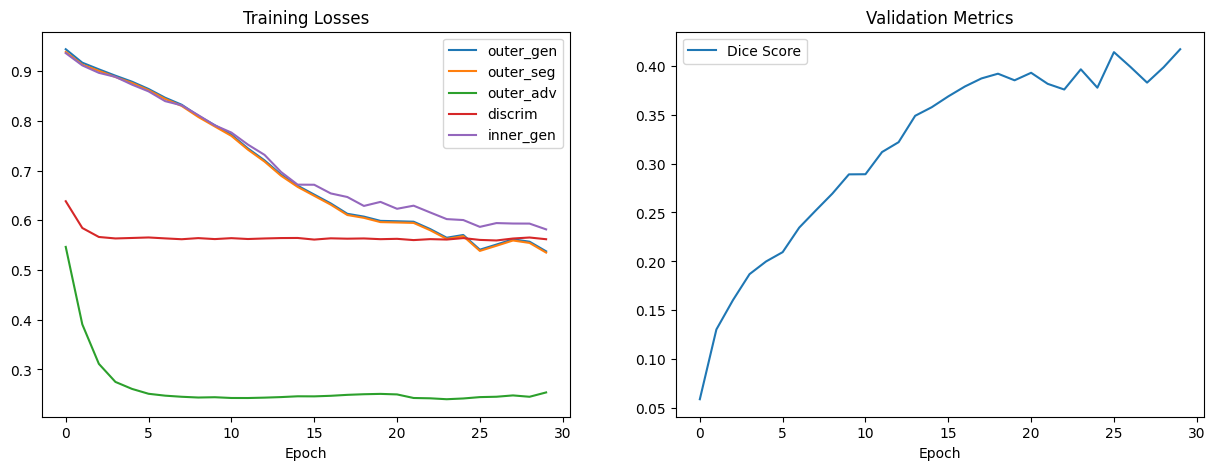


--- Evaluation Metrics ---


Evaluating: 100%|██████████| 50/50 [01:05<00:00,  1.31s/it]

      Dice  Accuracy  Precision  Recall      F1  Sensitivity  Specificity
WT  0.6725    0.9764     0.6723  0.7546  0.6725       0.7546       0.9867
TC  0.4812    0.9855     0.4104  0.7270  0.4812       0.7270       0.9897
ET  0.3492    0.9858     0.2545  0.6862  0.3492       0.6862       0.9883


In [3]:
# Define the path to your saved model
model_save_path = "/kaggle/working/best_model.pth"
print(f"INFO: Attempting to load model from: {model_save_path}")

# Define model parameters (should match training config)
INPUT_CHANNELS = 1
SEG_OUTPUT_CHANNELS = 3 
MODEL_FEATURE_SIZE = 32  # Must match what you used in training
ALL_MODS_TUPLE = ("flair", "t1", "t1ce", "t2")
USE_ADAPTERS = True
BATCH_SIZE_DF = 1  # Match your training setting

# Initialize model architecture
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the saved model
if os.path.exists(model_save_path):
    try:
        checkpoint = torch.load(model_save_path, map_location=device)
        
        # Initialize models
        segmentation_model_loaded = SegmentationModel(
            in_channels=INPUT_CHANNELS,
            out_channels=SEG_OUTPUT_CHANNELS,
            base_features=MODEL_FEATURE_SIZE,
            all_possible_modality_names=ALL_MODS_TUPLE,
            use_adapters_in_generator=USE_ADAPTERS
        ).to(device)
        
        segmentation_model_loaded.load_state_dict(checkpoint["segmentation_model"])
        print(f"Successfully loaded segmentation model from {model_save_path}")
        
        # Initialize a minimal discriminator just for evaluation compatibility
        dummy_discriminator = ModalityDiscriminator(
            bottleneck_feature_dim=segmentation_model_loaded.generator.encoder_feature_dims[-1],
            num_modalities=len(ALL_MODS_TUPLE)
        ).to(device)
        
        # Create a temporary trainer for evaluation
        class EvalTrainer:
            def __init__(self, segmentation_model, device):
                self.segmentation_model = segmentation_model
                self.device = device
                self.epoch_loss_history = {}
                self.epoch_dice_history = []
                self.epoch_hd_history = []
            
            def evaluate_metrics(self, dataloader, device):
                self.segmentation_model.eval()
                metrics = {
                    'WT': {'Dice': [], 'Accuracy': [], 'Precision': [], 
                          'Recall': [], 'F1': [], 'Sensitivity': [], 'Specificity': []},
                    'TC': {'Dice': [], 'Accuracy': [], 'Precision': [], 
                          'Recall': [], 'F1': [], 'Sensitivity': [], 'Specificity': []},
                    'ET': {'Dice': [], 'Accuracy': [], 'Precision': [], 
                          'Recall': [], 'F1': [], 'Sensitivity': [], 'Specificity': []}
                }
                
                with torch.no_grad():
                    for batch_data, _, seg_gt in tqdm(dataloader, desc="Evaluating"):
                        if seg_gt is None:
                            continue
                            
                        batch_data = {k: v.to(device) for k, v in batch_data.items()}
                        seg_gt = seg_gt.to(device)
                        
                        seg_logits, _ = self.segmentation_model(batch_data)
                        seg_pred = (torch.sigmoid(seg_logits) > 0.5).float()
                        
                        if seg_pred.shape[2:] != seg_gt.shape[2:]:
                            seg_gt = F.interpolate(seg_gt, size=seg_pred.shape[2:], mode='nearest')
                        
                        for i, name in enumerate(['WT', 'TC', 'ET']):
                            pred = seg_pred[:, i]
                            gt = seg_gt[:, i]
                            
                            # Calculate Dice
                            intersection = (pred * gt).sum()
                            union = pred.sum() + gt.sum()
                            dice = (2 * intersection) / (union + 1e-7)
                            metrics[name]['Dice'].append(dice.item())
                            
                            # Calculate other metrics
                            pred = pred.flatten()
                            gt = gt.flatten()
                            tp = (pred * gt).sum()
                            fp = (pred * (1 - gt)).sum()
                            tn = ((1 - pred) * (1 - gt)).sum()
                            fn = ((1 - pred) * gt).sum()
                            
                            eps = 1e-7
                            metrics[name]['Accuracy'].append(((tp + tn) / (tp + tn + fp + fn + eps)).item())
                            metrics[name]['Precision'].append((tp / (tp + fp + eps)).item())
                            metrics[name]['Recall'].append((tp / (tp + fn + eps)).item())
                            metrics[name]['F1'].append((2 * tp / (2 * tp + fp + fn + eps)).item())
                            metrics[name]['Sensitivity'].append((tp / (tp + fn + eps)).item())
                            metrics[name]['Specificity'].append((tn / (tn + fp + eps)).item())
                
                # Compute mean metrics
                final_metrics = {}
                for name in metrics:
                    final_metrics[name] = {
                        'Dice': np.mean(metrics[name]['Dice']),
                        'Accuracy': np.mean(metrics[name]['Accuracy']),
                        'Precision': np.mean(metrics[name]['Precision']),
                        'Recall': np.mean(metrics[name]['Recall']),
                        'F1': np.mean(metrics[name]['F1']),
                        'Sensitivity': np.mean(metrics[name]['Sensitivity']),
                        'Specificity': np.mean(metrics[name]['Specificity'])
                    }
                
                return final_metrics
            
        eval_trainer = EvalTrainer(segmentation_model_loaded, device)
        
        # --- Plot Training Curves ---
        if 'meta_trainer' in locals() and hasattr(meta_trainer, 'epoch_loss_history'):
            print("\n--- Training Curves ---")
            
            import matplotlib.pyplot as plt
            plt.figure(figsize=(15, 5))
            
            # Plot losses
            plt.subplot(1, 2, 1)
            for k, v in meta_trainer.epoch_loss_history.items():
                plt.plot(v, label=k)
            plt.title("Training Losses")
            plt.xlabel("Epoch")
            plt.legend()
            
            # Plot metrics
            plt.subplot(1, 2, 2)
            if hasattr(meta_trainer, 'epoch_dice_history'):
                plt.plot(meta_trainer.epoch_dice_history, label='Dice Score')
            plt.title("Validation Metrics")
            plt.xlabel("Epoch")
            plt.legend()
            plt.show()
        else:
            print("\nWARNING: Original trainer not found - can't plot training history")
        
        # --- Evaluate Metrics ---
        if 'dataset_Df' in locals():
            print("\n--- Evaluation Metrics ---")
            eval_dataloader = DataLoader(dataset_Df, batch_size=1, shuffle=False)
            metrics = eval_trainer.evaluate_metrics(eval_dataloader, device)
            
            # Pretty print metrics
            import pandas as pd
            print(pd.DataFrame(metrics).T.round(4))
        else:
            print("\nWARNING: dataset_Df not found - can't compute metrics")
        
    except Exception as e:
        print(f"ERROR during evaluation: {str(e)}")
        raise e  # Re-raise to see full traceback
else:
    print(f"Model file not found at {model_save_path}")

INFO: Attempting to load model from: /kaggle/working/best_model.pth
Successfully loaded model from /kaggle/working/best_model.pth

=== Detailed Metrics ===
+----------+--------+------------+-------------+----------+---------------+--------+
| Region   |   Dice |   Accuracy |   Precision |   Recall |   Specificity |     F1 |
+==========+========+============+=============+==========+===============+========+
| WT       | 0.8025 |     0.9771 |      0.9373 |   0.7016 |        0.9967 | 0.8025 |
+----------+--------+------------+-------------+----------+---------------+--------+
| TC       | 0.3114 |     0.9669 |      0.2804 |   0.3502 |        0.9804 | 0.3114 |
+----------+--------+------------+-------------+----------+---------------+--------+
| ET       | 0.3135 |     0.9753 |      0.2342 |   0.4736 |        0.9814 | 0.3135 |
+----------+--------+------------+-------------+----------+---------------+--------+
Ground Truth - WT: 138991.0, TC: 44770.0, ET: 24946.0
Predicted - WT: 104044, T

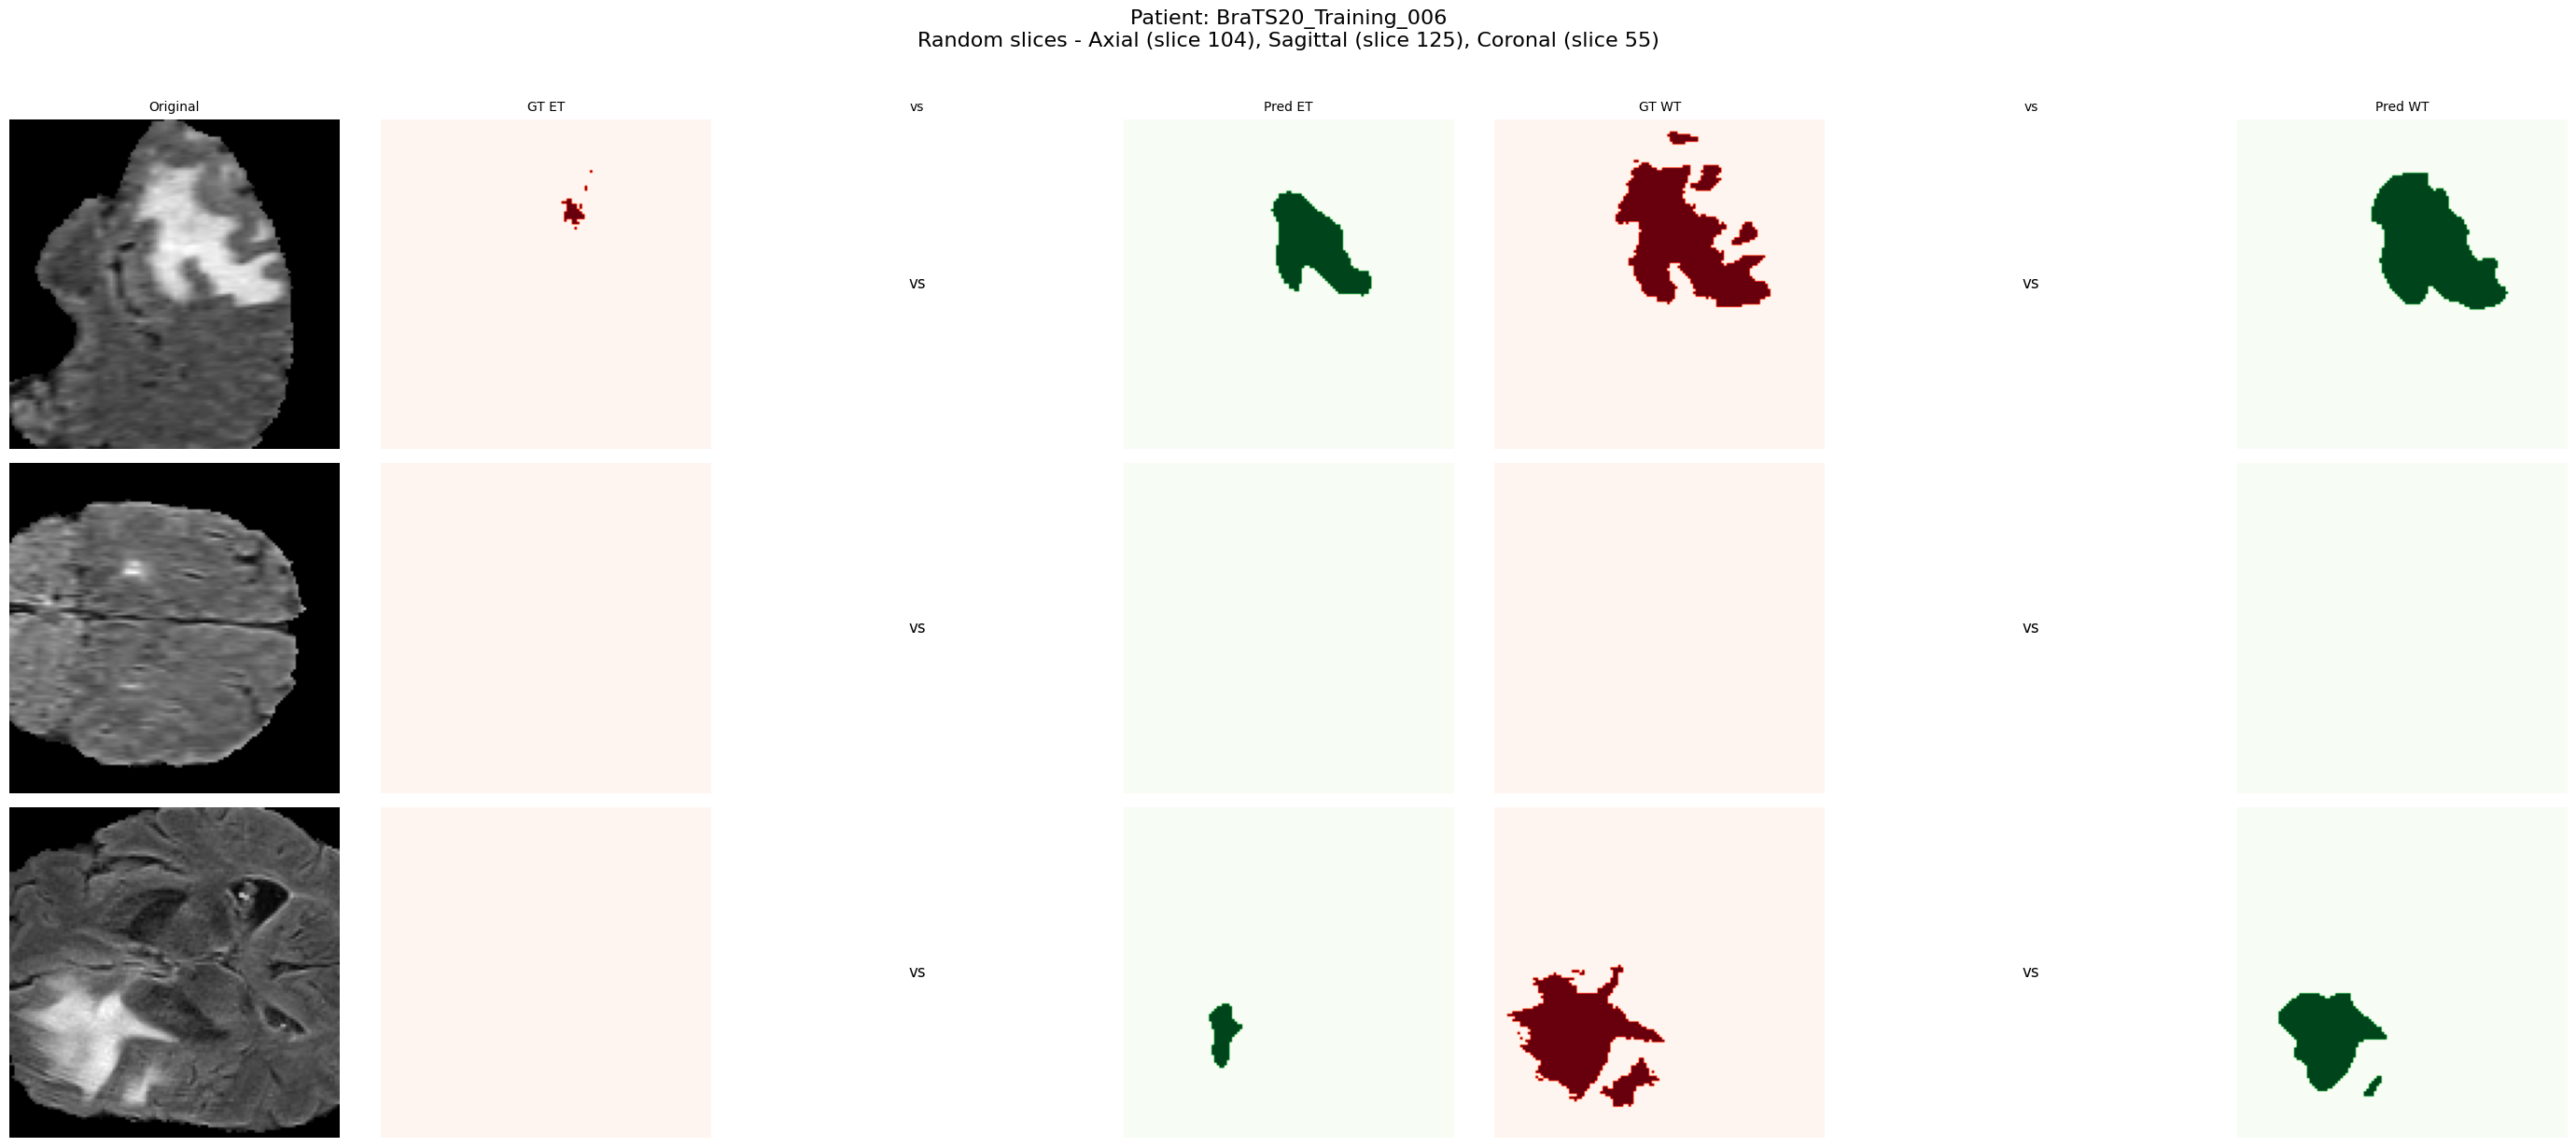

In [4]:
# Define the path to your saved model
model_save_path = "/kaggle/working/best_model.pth"
print(f"INFO: Attempting to load model from: {model_save_path}")

# Define model parameters (should match training config)
INPUT_CHANNELS = 1
SEG_OUTPUT_CHANNELS = 3 
MODEL_FEATURE_SIZE = 32
ALL_MODS_TUPLE = ("flair", "t1", "t1ce", "t2")
USE_ADAPTERS = True

# Initialize model architecture
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def visualize_patient(patient_dir, model, device, target_size=(128, 128, 128)):
    """Visualize predictions vs ground truth in 3 views with comparison slices"""
    import nibabel as nib
    import matplotlib.pyplot as plt
    import random
    
    # Load all modalities and ground truth
    patient_id = os.path.basename(patient_dir)
    modalities = {}
    
    # Load MRI modalities
    for mod in ALL_MODS_TUPLE:
        file_path = f"{patient_dir}/{patient_id}_{mod}.nii"
        if not os.path.exists(file_path):
            file_path += ".gz"
        if os.path.exists(file_path):
            img = nib.load(file_path).get_fdata()
            img = (img - img.min()) / (img.max() - img.min() + 1e-7)
            img = _preprocess_spatial_utility(img, target_size)
            modalities[mod] = img.astype(np.float32)
        else:
            modalities[mod] = np.zeros(target_size, dtype=np.float32)
    
    # Load ground truth if available
    seg_gt = None
    seg_path = f"{patient_dir}/{patient_id}_seg.nii"
    if not os.path.exists(seg_path):
        seg_path += ".gz"
    if os.path.exists(seg_path):
        seg_gt = nib.load(seg_path).get_fdata()
        seg_gt = _preprocess_spatial_utility(seg_gt, target_size)
        seg_gt = _create_multilabel_seg_masks_utility(seg_gt)
    
    # Prepare input and predict
    input_dict = {}
    for k, v in modalities.items():
        tensor = torch.from_numpy(v).float()
        input_dict[k] = tensor.unsqueeze(0).unsqueeze(0).to(device)
    
    with torch.no_grad():
        seg_logits, _ = model(input_dict)
        seg_pred = torch.sigmoid(seg_logits) > 0.5
    seg_pred_np = seg_pred.squeeze().cpu().numpy()

    if seg_gt is not None:
        print("\n=== Detailed Metrics ===")
        eps = 1e-7
        metrics_data = []
        
        for i, name in enumerate(['WT', 'TC', 'ET']):
            # Flatten predictions and ground truth
            pred_flat = seg_pred_np[i].flatten()
            gt_flat = seg_gt[i].flatten()
            
            # Calculate confusion matrix components
            tp = (pred_flat * gt_flat).sum()
            fp = (pred_flat * (1 - gt_flat)).sum()
            tn = ((1 - pred_flat) * (1 - gt_flat)).sum()
            fn = ((1 - pred_flat) * gt_flat).sum()
            
            # Calculate metrics
            metrics_data.append([
                name,
                (2 * tp) / (2 * tp + fp + fn + eps),  # Dice
                (tp + tn) / (tp + tn + fp + fn + eps),  # Accuracy
                tp / (tp + fp + eps),  # Precision
                tp / (tp + fn + eps),  # Recall/Sensitivity
                tn / (tn + fp + eps),  # Specificity
                (2 * (tp / (tp + fp + eps)) * (tp / (tp + fn + eps))) /  # Fixed F1
                ((tp / (tp + fp + eps)) + (tp / (tp + fn + eps)) + eps)  # F1
            ])
        
        # Create and display table
        from tabulate import tabulate
        headers = ["Region", "Dice", "Accuracy", "Precision", "Recall", "Specificity", "F1"]
        print(tabulate(metrics_data, headers=headers, floatfmt=".4f", tablefmt="grid"))
        
    # Calculate volumes
    if seg_gt is not None:
        gt_volumes = {
            'WT': np.sum(seg_gt[0]),
            'TC': np.sum(seg_gt[1]),
            'ET': np.sum(seg_gt[2])
        }
        print(f"Ground Truth - WT: {gt_volumes['WT']}, TC: {gt_volumes['TC']}, ET: {gt_volumes['ET']}")
    
    pred_volumes = {
        'WT': np.sum(seg_pred_np[0]),
        'TC': np.sum(seg_pred_np[1]),
        'ET': np.sum(seg_pred_np[2])
    }
    print(f"Predicted - WT: {pred_volumes['WT']}, TC: {pred_volumes['TC']}, ET: {pred_volumes['ET']}")

        
    # Print results summary
    print("\n=== Prediction Results ===")
    print(f"Patient: {patient_id}")
    print(f"Input shape: {modalities['flair'].shape}")
    
    # Select random slices for each view
    random.seed()  # Reseed to get different slices each time
    slices = {
        'axial': random.randint(0, target_size[0]-1),
        'sagittal': random.randint(0, target_size[1]-1),
        'coronal': random.randint(0, target_size[2]-1)
    }
    
    # Create figure with 3 rows (views) and 7 columns
    fig, axes = plt.subplots(3, 7, figsize=(28, 12))
    plt.suptitle(f"Patient: {patient_id}\nRandom slices - Axial (slice {slices['axial']}), "
                f"Sagittal (slice {slices['sagittal']}), Coronal (slice {slices['coronal']})", 
                y=1.02, fontsize=16)
    
    # Set column titles
    col_titles = ["Original", "GT ET", "vs", "Pred ET", 
                 "GT WT", "vs", "Pred WT", 
                 "GT TC", "vs", "Pred TC"]
    
    # Simplify column titles to fit better
    simple_col_titles = ["Original", "GT ET", "vs", "Pred ET", 
                        "GT WT", "vs", "Pred WT"]
    
    for ax, col_title in zip(axes[0], simple_col_titles):
        ax.set_title(col_title, fontsize=10)
    
    # Set row titles
    row_titles = ["Axial", "Sagittal", "Coronal"]
    for ax, row_title in zip(axes[:,0], row_titles):
        ax.set_ylabel(row_title, rotation=90, fontsize=12, labelpad=15)
    
    # Visualization function
    def plot_view(ax_row, view_slice, view_type):
        """Helper function to plot one view row"""
        if view_type == 'axial':
            original_slice = modalities['flair'][view_slice, :, :]
            if seg_gt is not None:
                gt_et = seg_gt[2, view_slice, :, :]
                gt_wt = seg_gt[0, view_slice, :, :]
                gt_tc = seg_gt[1, view_slice, :, :]
            pred_et = seg_pred_np[2, view_slice, :, :]
            pred_wt = seg_pred_np[0, view_slice, :, :]
            pred_tc = seg_pred_np[1, view_slice, :, :]
        elif view_type == 'sagittal':
            original_slice = modalities['flair'][:, view_slice, :]
            if seg_gt is not None:
                gt_et = seg_gt[2, :, view_slice, :]
                gt_wt = seg_gt[0, :, view_slice, :]
                gt_tc = seg_gt[1, :, view_slice, :]
            pred_et = seg_pred_np[2, :, view_slice, :]
            pred_wt = seg_pred_np[0, :, view_slice, :]
            pred_tc = seg_pred_np[1, :, view_slice, :]
        else:  # coronal
            original_slice = modalities['flair'][:, :, view_slice]
            if seg_gt is not None:
                gt_et = seg_gt[2, :, :, view_slice]
                gt_wt = seg_gt[0, :, :, view_slice]
                gt_tc = seg_gt[1, :, :, view_slice]
            pred_et = seg_pred_np[2, :, :, view_slice]
            pred_wt = seg_pred_np[0, :, :, view_slice]
            pred_tc = seg_pred_np[1, :, :, view_slice]
        
        # Original
        ax_row[0].imshow(original_slice, cmap='gray')
        
        # ET columns
        if seg_gt is not None:
            ax_row[1].imshow(gt_et, cmap='Reds', vmin=0, vmax=1)
        else:
            ax_row[1].imshow(np.zeros_like(original_slice), cmap='gray')
        
        # VS separator (just text)
        ax_row[2].text(0.5, 0.5, 'vs', ha='center', va='center', fontsize=12)
        ax_row[2].axis('off')
        
        ax_row[3].imshow(pred_et, cmap='Greens', vmin=0, vmax=1)
        
        # WT columns
        if seg_gt is not None:
            ax_row[4].imshow(gt_wt, cmap='Reds', vmin=0, vmax=1)
        else:
            ax_row[4].imshow(np.zeros_like(original_slice), cmap='gray')
        
        # VS separator (just text)
        ax_row[5].text(0.5, 0.5, 'vs', ha='center', va='center', fontsize=12)
        ax_row[5].axis('off')
        
        ax_row[6].imshow(pred_wt, cmap='Greens', vmin=0, vmax=1)
    
    # Plot each view
    plot_view(axes[0], slices['axial'], 'axial')
    plot_view(axes[1], slices['sagittal'], 'sagittal')
    plot_view(axes[2], slices['coronal'], 'coronal')
    
    # Turn off axis for all subplots
    for ax_row in axes:
        for ax in ax_row:
            ax.axis('off')
    
    plt.tight_layout()
    plt.show()

# Load the saved model
if os.path.exists(model_save_path):
    try:
        checkpoint = torch.load(model_save_path, map_location=device)
        
        segmentation_model = SegmentationModel(
            in_channels=INPUT_CHANNELS,
            out_channels=SEG_OUTPUT_CHANNELS,
            base_features=MODEL_FEATURE_SIZE,
            all_possible_modality_names=ALL_MODS_TUPLE,
            use_adapters_in_generator=USE_ADAPTERS
        ).to(device)
        
        segmentation_model.load_state_dict(checkpoint["segmentation_model"])
        print(f"Successfully loaded model from {model_save_path}")
        
        # Example usage with a patient directory
        patient_path = "/kaggle/input/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_006"
        if os.path.exists(patient_path):
            visualize_patient(patient_path, segmentation_model, device)
        else:
            print(f"\nPatient directory not found: {patient_path}")
        
    except Exception as e:
        print(f"ERROR during evaluation: {str(e)}")
        raise e
else:
    print(f"Model file not found at {model_save_path}")